# CropCop — Final Proof of Concept

## Data architecture

- **Multispectral satellite monitoring:** Real Sentinel-2 Level-2A imagery
- **Hyperspectral diagnosis:** Airborne hyperspectral imagery from the controlled field experiment
- **Thermal diagnosis:** Airborne canopy-temperature measurements providing complementary information related to water limitation
- **Ground truth:** Controlled nitrogen and water treatments, agronomic measurements, and Nitrogen Nutrition Index (NNI)

The PoC keeps the satellite-monitoring and controlled-diagnosis datasets explicitly separated.

Airborne hyperspectral data are **not** represented as real Sentinel-2 or Satellite 813 observations.

---

## What this PoC demonstrates

CropCop demonstrates two connected capabilities:

1. **Real-satellite monitoring and spatial-progression prediction**
2. **Hyperspectral-assisted stress-cause diagnosis**

Together, these form the proposed CropCop workflow:

**Detect → Diagnose → Predict spatial progression → Support earlier intervention**

---

## 1. Real-satellite monitoring and spatial-progression prediction

CropCop was demonstrated using a **real 14-date Sentinel-2 Level-2A time series** over the experimental field.

The satellite pipeline combines NDVI, NDRE and NDMI to characterize relative crop condition through time and uses temporal and spatial information to estimate where crop-condition weakness may appear at the next satellite observation.

### Strict new-weak-area prediction test

To test spatial progression more directly, the model was evaluated only on pixels that were **not currently weak**.

The question was:

> **Which currently non-weak pixels are most likely to become weak at the next Sentinel-2 observation?**

Across four rolling forecast origins, **16 newly weak pixel-events** were observed.

Mean prediction performance was:

- **ML model PR-AUC: 0.447**
- Current-condition baseline: **0.330**
- Neighbour-only baseline: **0.197**
- Trend-only baseline: **0.104**

The ML model therefore produced the highest observed mean PR-AUC.

However, spatial-block bootstrap uncertainty was wide. The improvement over current condition alone was:

**ΔPR-AUC = +0.117**  
**95% CI: -0.226 to +0.437**

The improvement was therefore promising but **not statistically conclusive**.

The PoC demonstrates a functioning **real-satellite next-observation spatial-risk prediction pipeline**, but does not claim a fully validated biological stress-spread forecasting advantage.

The prediction output is best interpreted as an **early-warning spatial risk map showing where crop-condition weakness may emerge next**.

---

## 2. Stress-cause diagnosis

Diagnosis was evaluated independently using **32 controlled winter-wheat plots** with known nitrogen and water treatments.

Four treatment-condition classes were evaluated:

- Reference
- Nitrogen deficiency
- Water stress
- Mixed stress

Using the same frozen repeated nested cross-validation protocol, four-state diagnosis accuracy was:

- **Airborne-derived Sentinel-2-compatible broad bands: 70.9%**
- **Full airborne hyperspectral: 79.1%**
- **Thermal only: 50.0%**
- **S2-compatible + thermal: 80.1%**
- **Hyperspectral + thermal: 80.4%**

Full hyperspectral information improved four-state treatment-condition diagnosis by approximately:

**+8.3 percentage points over the broad S2-compatible representation**  
**95% CI: approximately +2.0 to +14.8 pp**

Thermal information was particularly informative for the water-treatment distinction and provided complementary diagnostic information when combined with spectral data.

---

## 3. Satellite 813 relevance

To test whether the hyperspectral diagnostic information depended on the very dense spectral sampling of the airborne instrument, an additional **813-range 5-nm hyperspectral proxy** was created.

The airborne spectra were reduced to:

- **400–1700 nm spectral range**
- **approximately 5-nm sampling**

This represents the published spectral range and approximate sampling concept of Satellite 813.

The resulting proxy contained **221 spectral features** and achieved:

**79.2% four-state diagnosis accuracy**

Compared with the broad Sentinel-2-compatible representation:

**813-range proxy: 79.2%**  
**S2-compatible broad bands: 70.9%**

Difference:

**+8.4 percentage points**  
**95% CI: +1.9 to +15.2 pp**

The 813-range proxy also performed essentially identically to the full airborne hyperspectral representation:

**813-range proxy: 79.2%**  
**Full HSI: 79.1%**

There was no clear performance difference between those two representations.

This supports the conclusion that the diagnostic information observed in the controlled experiment was retained after reducing the spectra to an **813-relevant spectral range and sampling scale**.

### Important distinction

The 813-range proxy is **not real Satellite 813 imagery** and should not be interpreted as a validated Satellite 813 accuracy result.

It does not reproduce:

- the exact Satellite 813 spectral response functions
- atmospheric effects
- signal-to-noise characteristics
- 20-m spatial mixing
- real satellite acquisition conditions

It therefore demonstrates **spectral compatibility with the CropCop concept**, not operational Satellite 813 performance.

---

## 4. Why combine Sentinel-2 and hyperspectral information?

The two data types serve different purposes in the proposed CropCop architecture.

### Sentinel-2 — temporal monitoring and progression

Sentinel-2 provides repeated satellite observations that allow CropCop to:

- monitor crop condition across the field
- identify relatively weak areas
- track spatial changes through time
- estimate where new weakness may emerge at the next observation

### Hyperspectral information — diagnostic support

Hyperspectral measurements provide much denser spectral information than broad multispectral bands.

In the controlled treatment experiment, this richer spectral representation increased four-state treatment-condition diagnosis from **70.9% to approximately 79%**.

The 813-range 5-nm proxy retained that performance, supporting the use of hyperspectral information as a potential **diagnostic layer** within CropCop.

### Thermal information — complementary water-stress information

Canopy temperature provided particularly strong information related to the water-treatment condition.

The PoC therefore supports a **multi-sensor architecture**, rather than claiming that hyperspectral information alone is sufficient for every diagnostic task.

---

## 5. Robustness of the hyperspectral result

The hyperspectral advantage was **not universal**.

The primary diagnosis experiment defined nitrogen condition using the experimentally imposed fertilizer treatments.

As a sensitivity analysis, nitrogen deficiency was redefined using measured physiological nitrogen status:

**NNI ≤ 0.80**

Under this alternative definition:

- S2-compatible broad bands: **78.1%**
- Full HSI: **76.6%**

HSI − S2-compatible:

**-1.5 percentage points**  
**95% CI: approximately -6.5 to +3.1 pp**

Therefore, no hyperspectral advantage was demonstrated under the NNI-based definition.

This means the PoC supports hyperspectral information as a useful diagnostic layer for distinguishing the controlled treatment conditions, but does **not** claim that hyperspectral information is universally superior for every crop-stress definition.

---

## Important limitations

- The **real Sentinel-2 imagery** is the real-satellite component of the current PoC.
- The hyperspectral and thermal diagnosis measurements were collected from an **aircraft**, not from a satellite.
- The Sentinel-2-compatible diagnosis features were mathematically derived from airborne hyperspectral measurements using official Sentinel-2 spectral response functions. They are not real Sentinel-2 observations.
- The 813-range 5-nm proxy reproduces only an 813-relevant spectral range and sampling concept. It is not real Satellite 813 imagery.
- Exact geographic polygons for the 32 controlled experimental plots were unavailable, so the controlled diagnosis labels could not be reliably mapped directly onto individual real Sentinel-2 pixels.
- Satellite prediction and controlled stress-cause diagnosis are therefore validated at **two different spatial levels** in the current PoC.
- The Sentinel-2 progression target represents **relative satellite-observed crop condition**, not independently measured biological stress progression.
- Only **16 newly weak pixel-events** were available for the strict spatial-emergence prediction test.
- The prediction model did not demonstrate statistically conclusive superiority over current crop condition alone.
- The hyperspectral treatment-label advantage was not reproduced when nitrogen status was defined using NNI ≤ 0.80.
- Results come from **one experimental field and season** and require external multi-field and multi-season validation before operational deployment.

---

## Final PoC interpretation

The current PoC demonstrates the core technical architecture of CropCop:

**Real Sentinel-2 observations provide the temporal monitoring and spatial-progression layer.**

**Hyperspectral information provides additional diagnostic capability for distinguishing controlled nitrogen-, water- and mixed-treatment conditions.**

**An 813-range 5-nm spectral proxy retained the full hyperspectral diagnosis performance, supporting the relevance of Satellite 813-type spectral information to the proposed diagnostic layer.**

The next operational step would be to connect these layers using georeferenced plot-level or field-level ground truth across multiple fields and seasons so that satellite-observed progression and stress-cause diagnosis can be validated within the same spatial framework.

In [ ]:
# ============================================================
# Repository paths
# ============================================================

from pathlib import Path

# Works whether the notebook is launched from the repository
# root or from the notebooks/ folder.
CWD = Path.cwd()

if (CWD / "data" / "sample_input").exists():
    REPO_ROOT = CWD
elif (CWD.parent / "data" / "sample_input").exists():
    REPO_ROOT = CWD.parent
else:
    raise FileNotFoundError(
        "Could not find data/sample_input. "
        "Run this notebook from the cloned CropCop repository."
    )

DATA_DIR = REPO_ROOT / "data" / "sample_input"
RESULTS_DIR = REPO_ROOT / "results"
CACHE_DIR = REPO_ROOT / "runtime_cache"

RESULTS_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)

print("Repository root:", REPO_ROOT)
print("Input data:", DATA_DIR)

In [1]:
# ============================================================
# CropCop Final PoC — Setup
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Files currently uploaded:")
for f in sorted(os.listdir("/content")):
    if not f.startswith("."):
        print(" -", f)

Files currently uploaded:
 - CropCop_Real_Sentinel2
 - Crop_Reflectance_temp_from_Plane_Corrected.xlsx
 - Crop_agronomic_data_wheat.xlsx
 - S2_2019-03-10_10m.zip.zip
 - S2_2019-03-10_20m.zip.zip
 - S2_2019-04-12_10m.zip.zip
 - S2_2019-04-12_20m.zip.zip
 - S2_2019-05-14_10m.zip.zip
 - S2_2019-05-14_20m.zip.zip
 - Weather_Data_Aranjuez_01_01_2018_31_12_2020.xlsx
 - sample_data


In [2]:
# ============================================================
# Step 2 — Extract REAL Sentinel-2 downloads
# ============================================================

import os
import zipfile

S2_DIR = CACHE_DIR / "CropCop_Real_Sentinel2"
os.makedirs(S2_DIR, exist_ok=True)

zip_files = [
    "S2_2019-03-10_10m.zip.zip",
    "S2_2019-03-10_20m.zip.zip",
    "S2_2019-04-12_10m.zip.zip",
    "S2_2019-04-12_20m.zip.zip",
    "S2_2019-05-14_10m.zip.zip",
    "S2_2019-05-14_20m.zip.zip"
]

for filename in zip_files:
    zip_path = DATA_DIR / filename
    folder_name = filename.replace(".zip.zip", "")
    output_dir = os.path.join(S2_DIR, folder_name)

    os.makedirs(output_dir, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(output_dir)

    print(f"\n✓ Extracted: {filename}")

    for root, dirs, files in os.walk(output_dir):
        for f in sorted(files):
            if f.lower().endswith((".tif", ".tiff")):
                print("   ", f)

print("\nReal Sentinel-2 extraction complete.")


✓ Extracted: S2_2019-03-10_10m.zip.zip
    2019-03-10-00_00_2019-03-10-23_59_Sentinel-2_L2A_B02_(Raw).tiff
    2019-03-10-00_00_2019-03-10-23_59_Sentinel-2_L2A_B03_(Raw).tiff
    2019-03-10-00_00_2019-03-10-23_59_Sentinel-2_L2A_B04_(Raw).tiff
    2019-03-10-00_00_2019-03-10-23_59_Sentinel-2_L2A_B08_(Raw).tiff

✓ Extracted: S2_2019-03-10_20m.zip.zip
    2019-03-10-00_00_2019-03-10-23_59_Sentinel-2_L2A_B05_(Raw).tiff
    2019-03-10-00_00_2019-03-10-23_59_Sentinel-2_L2A_B06_(Raw).tiff
    2019-03-10-00_00_2019-03-10-23_59_Sentinel-2_L2A_B07_(Raw).tiff
    2019-03-10-00_00_2019-03-10-23_59_Sentinel-2_L2A_B11_(Raw).tiff
    2019-03-10-00_00_2019-03-10-23_59_Sentinel-2_L2A_B12_(Raw).tiff
    2019-03-10-00_00_2019-03-10-23_59_Sentinel-2_L2A_B8A_(Raw).tiff

✓ Extracted: S2_2019-04-12_10m.zip.zip
    2019-04-12-00_00_2019-04-12-23_59_Sentinel-2_L2A_B02_(Raw).tiff
    2019-04-12-00_00_2019-04-12-23_59_Sentinel-2_L2A_B03_(Raw).tiff
    2019-04-12-00_00_2019-04-12-23_59_Sentinel-2_L2A_B04_(Raw).t

In [3]:
# ============================================================
# Step 3 — Verify REAL Sentinel-2 band grids
# ============================================================

import os
import glob
import rasterio

DATES = ["2019-03-10", "2019-04-12", "2019-05-14"]

EXPECTED_10M = ["B02", "B03", "B04", "B08"]
EXPECTED_20M = ["B05", "B06", "B07", "B8A", "B11", "B12"]

s2_files = {}

for date in DATES:
    s2_files[date] = {}

    for resolution, expected_bands in [
        ("10m", EXPECTED_10M),
        ("20m", EXPECTED_20M)
    ]:

        folder = f"{S2_DIR}/S2_{date}_{resolution}"
        tif_files = glob.glob(os.path.join(folder, "**", "*.tiff"), recursive=True)

        band_paths = {}

        for band in expected_bands:
            matches = [
                p for p in tif_files
                if f"_L2A_{band}_" in os.path.basename(p)
            ]

            if len(matches) != 1:
                raise ValueError(
                    f"{date} {resolution} {band}: "
                    f"expected 1 file, found {len(matches)}"
                )

            band_paths[band] = matches[0]

        s2_files[date][resolution] = band_paths

        print(f"\n{date} — {resolution}")

        reference = None

        for band, path in band_paths.items():
            with rasterio.open(path) as src:

                info = (
                    src.width,
                    src.height,
                    src.crs,
                    src.transform
                )

                print(
                    f"  {band}: "
                    f"{src.width} × {src.height} | "
                    f"CRS={src.crs}"
                )

                if reference is None:
                    reference = info
                elif info != reference:
                    print(f"  ⚠ Grid mismatch detected for {band}")

        print("  ✓ Required bands found")

print("\nSentinel-2 grid verification complete.")


2019-03-10 — 10m
  B02: 23 × 22 | CRS=EPSG:32630
  B03: 23 × 22 | CRS=EPSG:32630
  B04: 23 × 22 | CRS=EPSG:32630
  B08: 23 × 22 | CRS=EPSG:32630
  ✓ Required bands found

2019-03-10 — 20m
  B05: 12 × 11 | CRS=EPSG:32630
  B06: 12 × 11 | CRS=EPSG:32630
  B07: 12 × 11 | CRS=EPSG:32630
  B8A: 12 × 11 | CRS=EPSG:32630
  B11: 12 × 11 | CRS=EPSG:32630
  B12: 12 × 11 | CRS=EPSG:32630
  ✓ Required bands found

2019-04-12 — 10m
  B02: 23 × 22 | CRS=EPSG:32630
  B03: 23 × 22 | CRS=EPSG:32630
  B04: 23 × 22 | CRS=EPSG:32630
  B08: 23 × 22 | CRS=EPSG:32630
  ✓ Required bands found

2019-04-12 — 20m
  B05: 12 × 11 | CRS=EPSG:32630
  B06: 12 × 11 | CRS=EPSG:32630
  B07: 12 × 11 | CRS=EPSG:32630
  B8A: 12 × 11 | CRS=EPSG:32630
  B11: 12 × 11 | CRS=EPSG:32630
  B12: 12 × 11 | CRS=EPSG:32630
  ✓ Required bands found

2019-05-14 — 10m
  B02: 23 × 22 | CRS=EPSG:32630
  B03: 23 × 22 | CRS=EPSG:32630
  B04: 23 × 22 | CRS=EPSG:32630
  B08: 23 × 22 | CRS=EPSG:32630
  ✓ Required bands found

2019-05-14 — 20m

In [4]:
# ============================================================
# Step 4 — Load REAL Sentinel-2 data and calculate indices
# ============================================================

import numpy as np
import pandas as pd
import rasterio

s2_data = {}

for date in DATES:

    # ---------- 10 m bands ----------
    bands10 = {}

    for band in EXPECTED_10M:
        with rasterio.open(s2_files[date]["10m"][band]) as src:
            bands10[band] = src.read(1).astype(float)

    # ---------- 20 m bands ----------
    bands20 = {}

    for band in EXPECTED_20M:
        with rasterio.open(s2_files[date]["20m"][band]) as src:
            bands20[band] = src.read(1).astype(float)

    # Valid crop/AOI pixels
    valid10 = np.ones_like(bands10["B02"], dtype=bool)
    for arr in bands10.values():
        valid10 &= np.isfinite(arr) & (arr > 0)

    valid20 = np.ones_like(bands20["B05"], dtype=bool)
    for arr in bands20.values():
        valid20 &= np.isfinite(arr) & (arr > 0)

    # ---------- Vegetation / moisture indices ----------

    # NDVI: vegetation condition
    NDVI = (
        (bands10["B08"] - bands10["B04"]) /
        (bands10["B08"] + bands10["B04"])
    )

    # NDRE: red-edge / chlorophyll-related condition
    NDRE = (
        (bands20["B8A"] - bands20["B05"]) /
        (bands20["B8A"] + bands20["B05"])
    )

    # NDMI: vegetation moisture-related condition
    NDMI = (
        (bands20["B8A"] - bands20["B11"]) /
        (bands20["B8A"] + bands20["B11"])
    )

    NDVI[~valid10] = np.nan
    NDRE[~valid20] = np.nan
    NDMI[~valid20] = np.nan

    s2_data[date] = {
        "bands10": bands10,
        "bands20": bands20,
        "valid10": valid10,
        "valid20": valid20,
        "NDVI": NDVI,
        "NDRE": NDRE,
        "NDMI": NDMI
    }


# ------------------------------------------------------------
# Require the SAME valid pixels across all three dates
# ------------------------------------------------------------

common_valid10 = np.logical_and.reduce(
    [s2_data[d]["valid10"] for d in DATES]
)

common_valid20 = np.logical_and.reduce(
    [s2_data[d]["valid20"] for d in DATES]
)

print("Common valid 10 m pixels:", common_valid10.sum())
print("Common valid 20 m pixels:", common_valid20.sum())


# ------------------------------------------------------------
# Summary of REAL Sentinel-2 observations
# ------------------------------------------------------------

rows = []

for date in DATES:

    rows.append({
        "Date": date,
        "Mean NDVI": np.nanmean(
            s2_data[date]["NDVI"][common_valid10]
        ),
        "Mean NDRE": np.nanmean(
            s2_data[date]["NDRE"][common_valid20]
        ),
        "Mean NDMI": np.nanmean(
            s2_data[date]["NDMI"][common_valid20]
        )
    })

s2_summary = pd.DataFrame(rows)

print("\nREAL SENTINEL-2 SUMMARY")
display(s2_summary.round(4))

Common valid 10 m pixels: 431
Common valid 20 m pixels: 117

REAL SENTINEL-2 SUMMARY


/tmp/ipykernel_6144/1976982204.py:40: RuntimeWarning: invalid value encountered in divide
  (bands10["B08"] - bands10["B04"]) /
/tmp/ipykernel_6144/1976982204.py:46: RuntimeWarning: invalid value encountered in divide
  (bands20["B8A"] - bands20["B05"]) /
/tmp/ipykernel_6144/1976982204.py:52: RuntimeWarning: invalid value encountered in divide
  (bands20["B8A"] - bands20["B11"]) /


,Date,Mean NDVI,Mean NDRE,Mean NDMI
0,2019-03-10,0.6991,0.5043,0.2029
1,2019-04-12,0.7356,0.5369,0.2945
2,2019-05-14,0.5890,0.4111,0.1880


REAL SENTINEL-2: APRIL 12 → MAY 14
Mean ΔNDVI: -0.1466
Mean ΔNDRE: -0.1257
Mean ΔNDMI: -0.1065


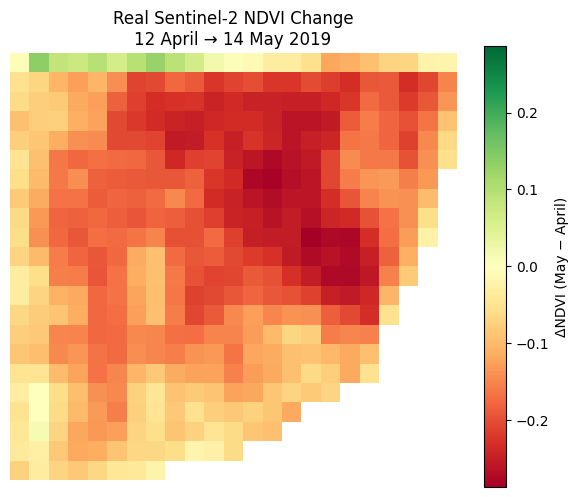

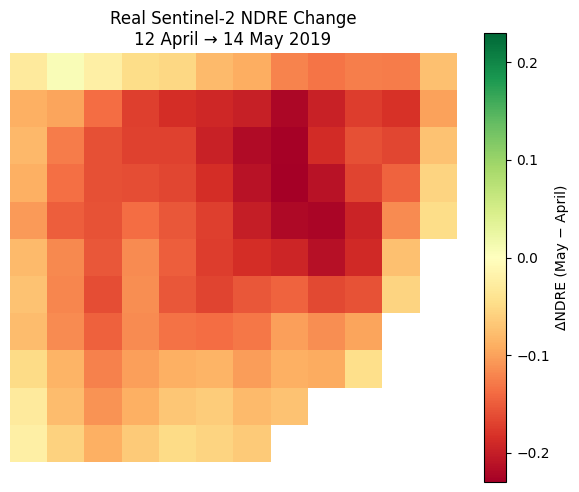

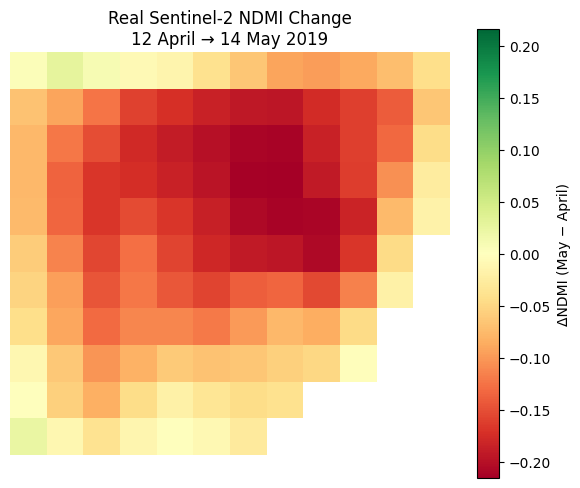

In [5]:
# ============================================================
# Step 5 — REAL Sentinel-2 April → May change maps
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Calculate change: May minus April
dNDVI = s2_data["2019-05-14"]["NDVI"] - s2_data["2019-04-12"]["NDVI"]
dNDRE = s2_data["2019-05-14"]["NDRE"] - s2_data["2019-04-12"]["NDRE"]
dNDMI = s2_data["2019-05-14"]["NDMI"] - s2_data["2019-04-12"]["NDMI"]

# Apply common valid masks
dNDVI[~common_valid10] = np.nan
dNDRE[~common_valid20] = np.nan
dNDMI[~common_valid20] = np.nan

print("REAL SENTINEL-2: APRIL 12 → MAY 14")
print(f"Mean ΔNDVI: {np.nanmean(dNDVI):.4f}")
print(f"Mean ΔNDRE: {np.nanmean(dNDRE):.4f}")
print(f"Mean ΔNDMI: {np.nanmean(dNDMI):.4f}")

# Plot each separately
for name, data in {
    "NDVI": dNDVI,
    "NDRE": dNDRE,
    "NDMI": dNDMI
}.items():

    plt.figure(figsize=(6, 5))

    vmax = np.nanmax(np.abs(data))

    plt.imshow(
        data,
        cmap="RdYlGn",
        vmin=-vmax,
        vmax=vmax
    )

    plt.colorbar(label=f"Δ{name} (May − April)")

    plt.title(
        f"Real Sentinel-2 {name} Change\n"
        "12 April → 14 May 2019"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

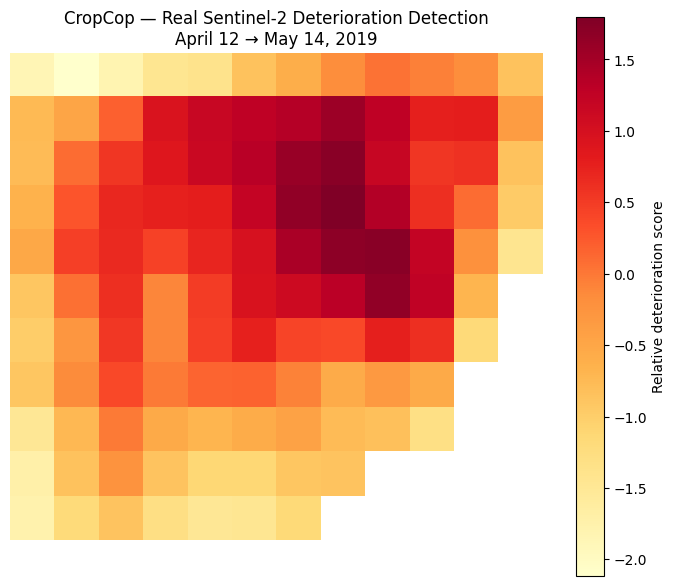

Pixels used: 117
Score range: -2.12 to 1.8


In [6]:
# ============================================================
# Step 6 — CropCop REAL Sentinel-2 deterioration score
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling

# ------------------------------------------------------------
# 1. Get geospatial information for the 10 m and 20 m grids
# ------------------------------------------------------------

with rasterio.open(s2_files["2019-05-14"]["10m"]["B04"]) as src:
    transform10 = src.transform
    crs10 = src.crs

with rasterio.open(s2_files["2019-05-14"]["20m"]["B05"]) as src:
    transform20 = src.transform
    crs20 = src.crs
    shape20 = (src.height, src.width)

# ------------------------------------------------------------
# 2. Resample ΔNDVI from 10 m → 20 m
# ------------------------------------------------------------

dNDVI_20m = np.full(shape20, np.nan, dtype=np.float32)

reproject(
    source=dNDVI.astype(np.float32),
    destination=dNDVI_20m,
    src_transform=transform10,
    src_crs=crs10,
    dst_transform=transform20,
    dst_crs=crs20,
    resampling=Resampling.average,
    src_nodata=np.nan,
    dst_nodata=np.nan
)

# Same valid area for all three signals
combined_valid = (
    np.isfinite(dNDVI_20m) &
    np.isfinite(dNDRE) &
    np.isfinite(dNDMI)
)

# ------------------------------------------------------------
# 3. Standardize each change signal
#    More negative change = stronger deterioration
# ------------------------------------------------------------

def zscore_valid(arr, mask):
    values = arr[mask]
    return (arr - np.mean(values)) / np.std(values)

z_ndvi = zscore_valid(dNDVI_20m, combined_valid)
z_ndre = zscore_valid(dNDRE, combined_valid)
z_ndmi = zscore_valid(dNDMI, combined_valid)

# Reverse sign:
# higher score = stronger deterioration
deterioration_score = -(
    z_ndvi + z_ndre + z_ndmi
) / 3

deterioration_score[~combined_valid] = np.nan

# ------------------------------------------------------------
# 4. Display
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

img = plt.imshow(
    deterioration_score,
    cmap="YlOrRd"
)

plt.colorbar(
    img,
    label="Relative deterioration score"
)

plt.title(
    "CropCop — Real Sentinel-2 Deterioration Detection\n"
    "April 12 → May 14, 2019"
)

plt.axis("off")
plt.tight_layout()
plt.show()

print("Pixels used:", combined_valid.sum())
print(
    "Score range:",
    round(np.nanmin(deterioration_score), 2),
    "to",
    round(np.nanmax(deterioration_score), 2)
)

In [7]:
# ============================================================
# Step 7 — Search REAL Sentinel-2 time series
# Microsoft Planetary Computer
# ============================================================


from pystac_client import Client
import planetary_computer
import pandas as pd

# La Chimenea Research Farm
LAT = 40.0649
LON = -3.5379

# Small search box around the experimental farm
BUFFER = 0.01

bbox = [
    LON - BUFFER,
    LAT - BUFFER,
    LON + BUFFER,
    LAT + BUFFER
]

# Public Planetary Computer STAC catalog
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

# Search the wheat growing period leading up to flowering
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime="2019-02-01/2019-05-20"
)

items = list(search.items())

rows = []

for item in items:
    rows.append({
        "Date": item.datetime.date().isoformat(),
        "Satellite": item.properties.get("platform"),
        "Cloud_cover_%": item.properties.get("eo:cloud_cover"),
        "Item_ID": item.id
    })

s2_catalog = (
    pd.DataFrame(rows)
    .sort_values(["Date", "Cloud_cover_%"])
    .reset_index(drop=True)
)

print("Sentinel-2 scenes found:", len(s2_catalog))
display(s2_catalog)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 9.5 MB/s eta 0:00:00
Sentinel-2 scenes found: 44


,Date,Satellite,Cloud_cover_%,Item_ID
0,2019-02-01,Sentinel-2A,44.662770,S2A_MSIL2A_20190201T111301_R137_T30TVK_2020100...
1,2019-02-03,Sentinel-2B,1.988243,S2B_MSIL2A_20190203T110249_R094_T30TVK_2020100...
2,2019-02-06,Sentinel-2B,0.346380,S2B_MSIL2A_20190206T111239_R137_T30TVK_2020100...
3,2019-02-08,Sentinel-2A,0.309020,S2A_MSIL2A_20190208T110221_R094_T30TVK_2020100...
4,2019-02-11,Sentinel-2A,4.176265,S2A_MSIL2A_20190211T111201_R137_T30TVK_2020100...
5,2019-02-13,Sentinel-2B,0.119320,S2B_MSIL2A_20190213T110149_R094_T30TVK_2020100...
6,2019-02-16,Sentinel-2B,1.431459,S2B_MSIL2A_20190216T111129_R137_T30TVK_2020100...
7,2019-02-18,Sentinel-2A,89.606908,S2A_MSIL2A_20190218T110111_R094_T30TVK_2020100...
8,2019-02-21,Sentinel-2A,0.332865,S2A_MSIL2A_20190221T111101_R137_T30TVK_2020100...
9,2019-02-23,Sentinel-2B,58.915261,S2B_MSIL2A_20190223T110039_R094_T30TVK_2020100...


In [8]:
# ============================================================
# Step 8 — First screening of REAL Sentinel-2 observations
# Keep scenes with <= 20% scene-level cloud cover
# ============================================================

import pandas as pd

s2_candidates = s2_catalog[
    s2_catalog["Cloud_cover_%"] <= 20
].copy()

s2_candidates["Date"] = pd.to_datetime(s2_candidates["Date"])

s2_candidates = (
    s2_candidates
    .sort_values("Date")
    .reset_index(drop=True)
)

s2_candidates["Days_since_previous"] = (
    s2_candidates["Date"]
    .diff()
    .dt.days
)

print("Low-cloud candidate scenes:", len(s2_candidates))

display(
    s2_candidates[
        [
            "Date",
            "Satellite",
            "Cloud_cover_%",
            "Days_since_previous",
            "Item_ID"
        ]
    ]
)

Low-cloud candidate scenes: 27


,Date,Satellite,Cloud_cover_%,Days_since_previous,Item_ID
0,2019-02-03,Sentinel-2B,1.988243,NaN,S2B_MSIL2A_20190203T110249_R094_T30TVK_2020100...
1,2019-02-06,Sentinel-2B,0.346380,3.0,S2B_MSIL2A_20190206T111239_R137_T30TVK_2020100...
2,2019-02-08,Sentinel-2A,0.309020,2.0,S2A_MSIL2A_20190208T110221_R094_T30TVK_2020100...
3,2019-02-11,Sentinel-2A,4.176265,3.0,S2A_MSIL2A_20190211T111201_R137_T30TVK_2020100...
4,2019-02-13,Sentinel-2B,0.119320,2.0,S2B_MSIL2A_20190213T110149_R094_T30TVK_2020100...
5,2019-02-16,Sentinel-2B,1.431459,3.0,S2B_MSIL2A_20190216T111129_R137_T30TVK_2020100...
6,2019-02-21,Sentinel-2A,0.332865,5.0,S2A_MSIL2A_20190221T111101_R137_T30TVK_2020100...
7,2019-02-26,Sentinel-2B,1.364551,5.0,S2B_MSIL2A_20190226T111049_R137_T30TVK_2020100...
8,2019-03-03,Sentinel-2A,16.605762,5.0,S2A_MSIL2A_20190303T110951_R137_T30TVK_2020103...
9,2019-03-08,Sentinel-2B,18.036161,5.0,S2B_MSIL2A_20190308T110909_R137_T30TVK_2020100...


In [9]:
# ============================================================
# Step 9 — Cloud screening over the MANUALLY DRAWN AOI
# Uses the valid footprint of your Sentinel-2 TIFF
# ============================================================

import numpy as np
import pandas as pd
import rasterio

from rasterio.features import shapes
from rasterio.mask import mask
from rasterio.warp import transform_geom
from shapely.geometry import shape, mapping
from shapely.ops import unary_union

# ------------------------------------------------------------
# 1. Reconstruct the manually drawn AOI from your downloaded TIFF
# ------------------------------------------------------------

reference_path = s2_files["2019-05-14"]["10m"]["B04"]

with rasterio.open(reference_path) as src:
    ref = src.read(1)

    # Valid pixels = inside your manually drawn AOI
    valid_mask = np.isfinite(ref) & (ref > 0)

    polygons = []

    for geom, value in shapes(
        valid_mask.astype(np.uint8),
        mask=valid_mask,
        transform=src.transform
    ):
        if value == 1:
            polygons.append(shape(geom))

    aoi_geom = unary_union(polygons)
    aoi_crs = src.crs

print("✓ Manual AOI footprint reconstructed from downloaded TIFF")
print("AOI CRS:", aoi_crs)


# ------------------------------------------------------------
# 2. SCL classes treated as unusable
# ------------------------------------------------------------

BAD_SCL = [0, 1, 3, 8, 9, 10, 11]

quality_rows = []

candidate_ids = set(s2_candidates["Item_ID"])


# ------------------------------------------------------------
# 3. Check every candidate scene over THIS AOI only
# ------------------------------------------------------------

for item in items:

    if item.id not in candidate_ids:
        continue

    scl_key = next(
        (k for k in item.assets if k.lower() == "scl"),
        None
    )

    if scl_key is None:
        continue

    try:
        with rasterio.open(item.assets[scl_key].href) as src:

            geom_scene = transform_geom(
                aoi_crs,
                src.crs,
                mapping(aoi_geom)
            )

            scl, _ = mask(
                src,
                [geom_scene],
                crop=True,
                filled=False
            )

            values = scl[0]

            valid = ~values.mask

            if valid.sum() == 0:
                continue

            scl_values = values.data[valid]

            bad_fraction = np.isin(
                scl_values,
                BAD_SCL
            ).mean()

            quality_rows.append({
                "Date": item.datetime.date().isoformat(),
                "Satellite": item.properties.get("platform"),
                "Scene_cloud_%": item.properties.get("eo:cloud_cover"),
                "AOI_clear_%": (1 - bad_fraction) * 100,
                "AOI_bad_%": bad_fraction * 100,
                "Item_ID": item.id
            })

    except Exception as e:
        print("Could not process:", item.id)
        print(" ", e)


farm_quality = pd.DataFrame(quality_rows)

farm_quality["Date"] = pd.to_datetime(
    farm_quality["Date"]
)

farm_quality = (
    farm_quality
    .sort_values("Date")
    .reset_index(drop=True)
)

print("\nREAL SENTINEL-2 QUALITY OVER MANUALLY DRAWN AOI")

display(
    farm_quality.round({
        "Scene_cloud_%": 2,
        "AOI_clear_%": 1,
        "AOI_bad_%": 1
    })
)

✓ Manual AOI footprint reconstructed from downloaded TIFF
AOI CRS: EPSG:32630

REAL SENTINEL-2 QUALITY OVER MANUALLY DRAWN AOI


,Date,Satellite,Scene_cloud_%,AOI_clear_%,AOI_bad_%,Item_ID
0,2019-02-03,Sentinel-2B,1.99,100.0,0.0,S2B_MSIL2A_20190203T110249_R094_T30TVK_2020100...
1,2019-02-06,Sentinel-2B,0.35,100.0,0.0,S2B_MSIL2A_20190206T111239_R137_T30TVK_2020100...
2,2019-02-08,Sentinel-2A,0.31,100.0,0.0,S2A_MSIL2A_20190208T110221_R094_T30TVK_2020100...
3,2019-02-11,Sentinel-2A,4.18,0.0,100.0,S2A_MSIL2A_20190211T111201_R137_T30TVK_2020100...
4,2019-02-13,Sentinel-2B,0.12,100.0,0.0,S2B_MSIL2A_20190213T110149_R094_T30TVK_2020100...
5,2019-02-16,Sentinel-2B,1.43,100.0,0.0,S2B_MSIL2A_20190216T111129_R137_T30TVK_2020100...
6,2019-02-21,Sentinel-2A,0.33,100.0,0.0,S2A_MSIL2A_20190221T111101_R137_T30TVK_2020100...
7,2019-02-26,Sentinel-2B,1.36,100.0,0.0,S2B_MSIL2A_20190226T111049_R137_T30TVK_2020100...
8,2019-03-03,Sentinel-2A,16.61,100.0,0.0,S2A_MSIL2A_20190303T110951_R137_T30TVK_2020103...
9,2019-03-08,Sentinel-2B,18.04,100.0,0.0,S2B_MSIL2A_20190308T110909_R137_T30TVK_2020100...


In [10]:
# ============================================================
# Step 10 — Lock usable REAL Sentinel-2 time-series scenes
# ============================================================

usable_s2 = (
    farm_quality[
        farm_quality["AOI_clear_%"] >= 90
    ]
    .copy()
    .sort_values("Date")
    .reset_index(drop=True)
)

usable_s2["Days_since_previous"] = (
    usable_s2["Date"].diff().dt.days
)

print("Usable real Sentinel-2 scenes:", len(usable_s2))
print(
    "Time span:",
    usable_s2["Date"].min().date(),
    "→",
    usable_s2["Date"].max().date()
)

display(
    usable_s2[
        [
            "Date",
            "Satellite",
            "AOI_clear_%",
            "Days_since_previous",
            "Item_ID"
        ]
    ]
)

Usable real Sentinel-2 scenes: 26
Time span: 2019-02-03 → 2019-05-14


,Date,Satellite,AOI_clear_%,Days_since_previous,Item_ID
0,2019-02-03,Sentinel-2B,100.0,NaN,S2B_MSIL2A_20190203T110249_R094_T30TVK_2020100...
1,2019-02-06,Sentinel-2B,100.0,3.0,S2B_MSIL2A_20190206T111239_R137_T30TVK_2020100...
2,2019-02-08,Sentinel-2A,100.0,2.0,S2A_MSIL2A_20190208T110221_R094_T30TVK_2020100...
3,2019-02-13,Sentinel-2B,100.0,5.0,S2B_MSIL2A_20190213T110149_R094_T30TVK_2020100...
4,2019-02-16,Sentinel-2B,100.0,3.0,S2B_MSIL2A_20190216T111129_R137_T30TVK_2020100...
5,2019-02-21,Sentinel-2A,100.0,5.0,S2A_MSIL2A_20190221T111101_R137_T30TVK_2020100...
6,2019-02-26,Sentinel-2B,100.0,5.0,S2B_MSIL2A_20190226T111049_R137_T30TVK_2020100...
7,2019-03-03,Sentinel-2A,100.0,5.0,S2A_MSIL2A_20190303T110951_R137_T30TVK_2020103...
8,2019-03-08,Sentinel-2B,100.0,5.0,S2B_MSIL2A_20190308T110909_R137_T30TVK_2020100...
9,2019-03-10,Sentinel-2A,100.0,2.0,S2A_MSIL2A_20190310T105851_R094_T30TVK_2020100...


In [11]:
# ============================================================
# Step 11 — Audit Sentinel-2 orbit and band metadata
# before building the full time series
# ============================================================

import pandas as pd
import rasterio
import numpy as np

# Map STAC item IDs back to items
items_by_id = {item.id: item for item in items}

audit_rows = []

for _, row in usable_s2.iterrows():

    item = items_by_id[row["Item_ID"]]

    audit_rows.append({
        "Date": row["Date"],
        "Satellite": item.properties.get("platform"),
        "Relative_orbit": item.properties.get("sat:relative_orbit"),
        "Item_ID": item.id
    })

orbit_audit = pd.DataFrame(audit_rows)

print("REAL SENTINEL-2 ORBIT DISTRIBUTION")
display(
    orbit_audit.groupby("Relative_orbit")
    .size()
    .rename("Number_of_scenes")
    .reset_index()
)

print("\nDATES BY ORBIT")
display(
    orbit_audit[
        ["Date", "Satellite", "Relative_orbit"]
    ]
)


# ------------------------------------------------------------
# Inspect one band's actual stored values + metadata
# ------------------------------------------------------------

example_item = items_by_id[usable_s2.iloc[0]["Item_ID"]]
asset = example_item.assets["B04"]

print("\nEXAMPLE B04 ASSET")
print("Item:", example_item.id)
print("Asset title:", asset.title)

raster_meta = asset.extra_fields.get("raster:bands", [{}])[0]

print("Metadata scale:", raster_meta.get("scale"))
print("Metadata offset:", raster_meta.get("offset"))

with rasterio.open(asset.href) as src:
    print("Raster dtype:", src.dtypes[0])
    print("CRS:", src.crs)
    print("Pixel size:", src.res)

REAL SENTINEL-2 ORBIT DISTRIBUTION


,Relative_orbit,Number_of_scenes
0,94,12
1,137,14



DATES BY ORBIT


,Date,Satellite,Relative_orbit
0,2019-02-03,Sentinel-2B,94
1,2019-02-06,Sentinel-2B,137
2,2019-02-08,Sentinel-2A,94
3,2019-02-13,Sentinel-2B,94
4,2019-02-16,Sentinel-2B,137
5,2019-02-21,Sentinel-2A,137
6,2019-02-26,Sentinel-2B,137
7,2019-03-03,Sentinel-2A,137
8,2019-03-08,Sentinel-2B,137
9,2019-03-10,Sentinel-2A,94



EXAMPLE B04 ASSET
Item: S2B_MSIL2A_20190203T110249_R094_T30TVK_20201007T134538
Asset title: Band 4 - Red - 10m
Metadata scale: None
Metadata offset: None
Raster dtype: uint16
CRS: EPSG:32630
Pixel size: (10.0, 10.0)


In [12]:
# ============================================================
# Step 12 — Lock primary REAL Sentinel-2 time series
# Use one relative orbit to avoid viewing-geometry changes
# ============================================================

PRIMARY_ORBIT = 137

primary_s2 = (
    usable_s2[
        usable_s2["Item_ID"].map(
            lambda x: items_by_id[x].properties.get("sat:relative_orbit")
        ) == PRIMARY_ORBIT
    ]
    .copy()
    .sort_values("Date")
    .reset_index(drop=True)
)

primary_s2["Days_since_previous"] = (
    primary_s2["Date"].diff().dt.days
)

print("PRIMARY CROP-COP SENTINEL-2 TIME SERIES")
print("Relative orbit:", PRIMARY_ORBIT)
print("Number of scenes:", len(primary_s2))
print(
    "Date range:",
    primary_s2["Date"].min().date(),
    "→",
    primary_s2["Date"].max().date()
)

display(
    primary_s2[
        [
            "Date",
            "Satellite",
            "AOI_clear_%",
            "Days_since_previous",
            "Item_ID"
        ]
    ]
)

PRIMARY CROP-COP SENTINEL-2 TIME SERIES
Relative orbit: 137
Number of scenes: 14
Date range: 2019-02-06 → 2019-05-12


,Date,Satellite,AOI_clear_%,Days_since_previous,Item_ID
0,2019-02-06,Sentinel-2B,100.0,NaN,S2B_MSIL2A_20190206T111239_R137_T30TVK_2020100...
1,2019-02-16,Sentinel-2B,100.0,10.0,S2B_MSIL2A_20190216T111129_R137_T30TVK_2020100...
2,2019-02-21,Sentinel-2A,100.0,5.0,S2A_MSIL2A_20190221T111101_R137_T30TVK_2020100...
3,2019-02-26,Sentinel-2B,100.0,5.0,S2B_MSIL2A_20190226T111049_R137_T30TVK_2020100...
4,2019-03-03,Sentinel-2A,100.0,5.0,S2A_MSIL2A_20190303T110951_R137_T30TVK_2020103...
5,2019-03-08,Sentinel-2B,100.0,5.0,S2B_MSIL2A_20190308T110909_R137_T30TVK_2020100...
6,2019-03-13,Sentinel-2A,100.0,5.0,S2A_MSIL2A_20190313T110831_R137_T30TVK_2020100...
7,2019-03-18,Sentinel-2B,100.0,5.0,S2B_MSIL2A_20190318T110759_R137_T30TVK_2020100...
8,2019-03-23,Sentinel-2A,100.0,5.0,S2A_MSIL2A_20190323T110721_R137_T30TVK_2020110...
9,2019-03-28,Sentinel-2B,100.0,5.0,S2B_MSIL2A_20190328T111049_R137_T30TVK_2020100...


In [13]:
# ============================================================
# Step 13 — Verify Planetary Computer data against
# manually downloaded Sentinel-2 data
# Same date: 12 April 2019
# ============================================================

import numpy as np
import pandas as pd
import rasterio

from rasterio.mask import mask
from rasterio.warp import transform_geom
from shapely.geometry import mapping

DATE_CHECK = pd.Timestamp("2019-04-12")

# ------------------------------------------------------------
# 1. Find April 12 scene in our primary orbit
# ------------------------------------------------------------

row = primary_s2[
    primary_s2["Date"] == DATE_CHECK
].iloc[0]

item = items_by_id[row["Item_ID"]]

print("Planetary Computer scene:")
print(item.id)


# ------------------------------------------------------------
# 2. Read B04 from Planetary Computer over our manual AOI
# ------------------------------------------------------------

pc_b04_path = item.assets["B04"].href

with rasterio.open(pc_b04_path) as src:

    geom_scene = transform_geom(
        aoi_crs,
        src.crs,
        mapping(aoi_geom)
    )

    pc_b04, _ = mask(
        src,
        [geom_scene],
        crop=True,
        filled=False
    )

    pc_values = pc_b04[0].compressed().astype(float)

    # Remove zero / no-data values
    pc_values = pc_values[
        np.isfinite(pc_values) & (pc_values > 0)
    ]


# ------------------------------------------------------------
# 3. Read B04 from YOUR manually downloaded April 12 TIFF
# ------------------------------------------------------------

manual_b04_path = s2_files["2019-04-12"]["10m"]["B04"]

with rasterio.open(manual_b04_path) as src:

    manual_b04 = src.read(1).astype(float)

    manual_values = manual_b04[
        np.isfinite(manual_b04) & (manual_b04 > 0)
    ]


# ------------------------------------------------------------
# 4. Compare
# ------------------------------------------------------------

print("\nRAW PLANETARY COMPUTER B04")
print("Pixels:", len(pc_values))
print("Min:", np.min(pc_values))
print("Mean:", np.mean(pc_values))
print("Max:", np.max(pc_values))

print("\nMANUAL COPERNICUS B04")
print("Pixels:", len(manual_values))
print("Min:", np.min(manual_values))
print("Mean:", np.mean(manual_values))
print("Max:", np.max(manual_values))

# Test standard Sentinel-2 scaling
pc_reflectance = pc_values / 10000.0

print("\nPLANETARY COMPUTER B04 / 10000")
print("Min:", np.min(pc_reflectance))
print("Mean:", np.mean(pc_reflectance))
print("Max:", np.max(pc_reflectance))

print("\nMean difference vs manual export:",
      abs(np.mean(pc_reflectance) - np.mean(manual_values)))

Planetary Computer scene:
S2A_MSIL2A_20190412T110621_R137_T30TVK_20201007T011010

RAW PLANETARY COMPUTER B04
Pixels: 431
Min: 294.0
Mean: 595.9791183294664
Max: 1432.0

MANUAL COPERNICUS B04
Pixels: 431
Min: 0.02979999966919422
Mean: 0.0591238979163759
Max: 0.147599995136261

PLANETARY COMPUTER B04 / 10000
Min: 0.0294
Mean: 0.05959791183294664
Max: 0.1432

Mean difference vs manual export: 0.00047401391657073827


In [14]:
# ============================================================
# Step 14 — Extract PRIMARY REAL Sentinel-2 time series
# 14 scenes, orbit 137, exact manual AOI
# ============================================================

import numpy as np
import pandas as pd
import rasterio

from rasterio.warp import reproject, Resampling

# ------------------------------------------------------------
# 1. Reference grids from YOUR manually downloaded AOI
# ------------------------------------------------------------

ref10_path = s2_files["2019-05-14"]["10m"]["B04"]
ref20_path = s2_files["2019-05-14"]["20m"]["B05"]

with rasterio.open(ref10_path) as src:
    ref10_shape = (src.height, src.width)
    ref10_transform = src.transform
    ref10_crs = src.crs
    ref10_data = src.read(1)
    manual_mask10 = np.isfinite(ref10_data) & (ref10_data > 0)

with rasterio.open(ref20_path) as src:
    ref20_shape = (src.height, src.width)
    ref20_transform = src.transform
    ref20_crs = src.crs
    ref20_data = src.read(1)
    manual_mask20 = np.isfinite(ref20_data) & (ref20_data > 0)


# ------------------------------------------------------------
# 2. Helper: read a real Sentinel-2 band onto our fixed grid
# ------------------------------------------------------------

def read_band_to_grid(item, band, shape, transform, crs):

    destination = np.full(
        shape,
        np.nan,
        dtype=np.float32
    )

    with rasterio.open(item.assets[band].href) as src:

        source = src.read(1).astype(np.float32)

        reproject(
            source=source,
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=transform,
            dst_crs=crs,
            src_nodata=0,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear
        )

    # Sentinel-2 L2A DN → surface reflectance
    destination = destination / 10000.0

    return destination


# ------------------------------------------------------------
# 3. Extract all 14 real Sentinel-2 scenes
# ------------------------------------------------------------

real_s2_series = {}
summary_rows = []

for _, row in primary_s2.iterrows():

    date = row["Date"].strftime("%Y-%m-%d")
    item = items_by_id[row["Item_ID"]]

    # 10 m
    B04 = read_band_to_grid(
        item, "B04",
        ref10_shape,
        ref10_transform,
        ref10_crs
    )

    B08 = read_band_to_grid(
        item, "B08",
        ref10_shape,
        ref10_transform,
        ref10_crs
    )

    # 20 m
    B05 = read_band_to_grid(
        item, "B05",
        ref20_shape,
        ref20_transform,
        ref20_crs
    )

    B8A = read_band_to_grid(
        item, "B8A",
        ref20_shape,
        ref20_transform,
        ref20_crs
    )

    B11 = read_band_to_grid(
        item, "B11",
        ref20_shape,
        ref20_transform,
        ref20_crs
    )

    # ----------------------------------------
    # Indices
    # ----------------------------------------

    with np.errstate(divide="ignore", invalid="ignore"):

        NDVI = (B08 - B04) / (B08 + B04)

        NDRE = (B8A - B05) / (B8A + B05)

        NDMI = (B8A - B11) / (B8A + B11)

    # Apply exact manually drawn AOI footprint
    NDVI[~manual_mask10] = np.nan
    NDRE[~manual_mask20] = np.nan
    NDMI[~manual_mask20] = np.nan

    real_s2_series[date] = {
        "NDVI": NDVI,
        "NDRE": NDRE,
        "NDMI": NDMI
    }

    summary_rows.append({
        "Date": pd.Timestamp(date),
        "Mean_NDVI": np.nanmean(NDVI),
        "Mean_NDRE": np.nanmean(NDRE),
        "Mean_NDMI": np.nanmean(NDMI),
        "Valid_10m": np.isfinite(NDVI).sum(),
        "Valid_20m": np.isfinite(NDRE).sum()
    })

    print("✓", date)


# ------------------------------------------------------------
# 4. Final real-satellite time-series table
# ------------------------------------------------------------

real_s2_timeseries = pd.DataFrame(summary_rows)

print("\nREAL SENTINEL-2 TIME SERIES COMPLETE")
display(real_s2_timeseries.round(4))

✓ 2019-02-06
✓ 2019-02-16
✓ 2019-02-21
✓ 2019-02-26
✓ 2019-03-03
✓ 2019-03-08
✓ 2019-03-13
✓ 2019-03-18
✓ 2019-03-23
✓ 2019-03-28
✓ 2019-04-12
✓ 2019-04-27
✓ 2019-05-02
✓ 2019-05-12

REAL SENTINEL-2 TIME SERIES COMPLETE


,Date,Mean_NDVI,Mean_NDRE,Mean_NDMI,Valid_10m,Valid_20m
0,2019-02-06,0.4301,0.2831,-0.0061,431,117
1,2019-02-16,0.5231,0.3623,0.0676,431,117
2,2019-02-21,0.5524,0.3884,0.1141,431,117
3,2019-02-26,0.6058,0.4373,0.1314,431,117
4,2019-03-03,0.6486,0.4702,0.1894,431,117
5,2019-03-08,0.6861,0.5064,0.2016,431,117
6,2019-03-13,0.7161,0.5301,0.2501,431,117
7,2019-03-18,0.7305,0.5484,0.2433,431,117
8,2019-03-23,0.7034,0.5199,0.2851,431,117
9,2019-03-28,0.7287,0.5480,0.2627,431,117


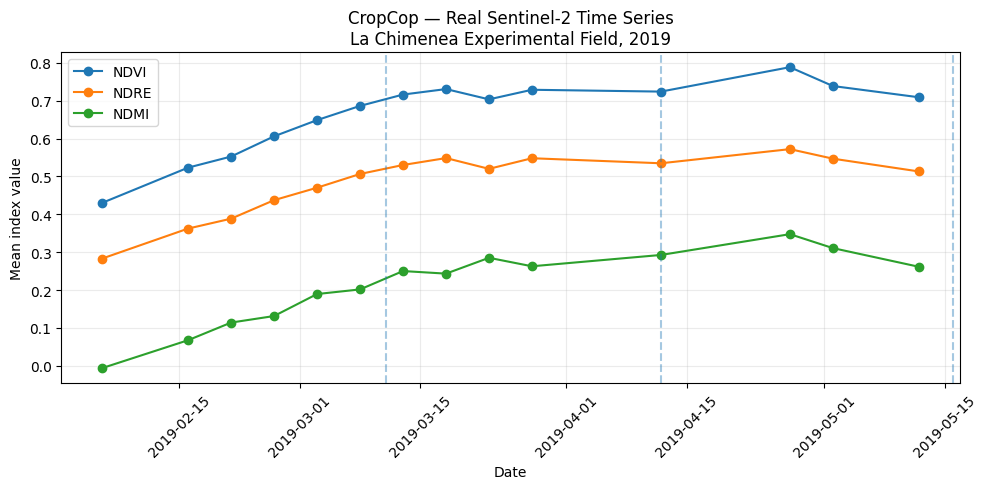

In [15]:
# ============================================================
# Step 15 — Visualize REAL Sentinel-2 crop-condition time series
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

ts = real_s2_timeseries.copy()

plt.figure(figsize=(10, 5))

plt.plot(
    ts["Date"],
    ts["Mean_NDVI"],
    marker="o",
    label="NDVI"
)

plt.plot(
    ts["Date"],
    ts["Mean_NDRE"],
    marker="o",
    label="NDRE"
)

plt.plot(
    ts["Date"],
    ts["Mean_NDMI"],
    marker="o",
    label="NDMI"
)

# Ground measurement dates
for d in [
    pd.Timestamp("2019-03-11"),
    pd.Timestamp("2019-04-12"),
    pd.Timestamp("2019-05-16")
]:
    plt.axvline(
        d,
        linestyle="--",
        alpha=0.4
    )

plt.xlabel("Date")
plt.ylabel("Mean index value")
plt.title(
    "CropCop — Real Sentinel-2 Time Series\n"
    "La Chimenea Experimental Field, 2019"
)

plt.legend()
plt.grid(alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [16]:
# ============================================================
# Step 16 — Build pixel-level REAL Sentinel-2 time series
# Common 20 m grid for NDVI + NDRE + NDMI
# ============================================================

import numpy as np
import pandas as pd
from rasterio.warp import reproject, Resampling
from rasterio.transform import xy

pixel_rows = []

for date, data in real_s2_series.items():

    # --------------------------------------------------------
    # Resample this date's 10 m NDVI → fixed 20 m grid
    # --------------------------------------------------------

    ndvi20 = np.full(
        ref20_shape,
        np.nan,
        dtype=np.float32
    )

    reproject(
        source=data["NDVI"].astype(np.float32),
        destination=ndvi20,
        src_transform=ref10_transform,
        src_crs=ref10_crs,
        dst_transform=ref20_transform,
        dst_crs=ref20_crs,
        src_nodata=np.nan,
        dst_nodata=np.nan,
        resampling=Resampling.average
    )

    ndre = data["NDRE"]
    ndmi = data["NDMI"]

    # Only locations containing all three measurements
    valid = (
        manual_mask20 &
        np.isfinite(ndvi20) &
        np.isfinite(ndre) &
        np.isfinite(ndmi)
    )

    for r, c in zip(*np.where(valid)):

        # Geographic position of 20 m pixel centre
        x, y = xy(
            ref20_transform,
            r,
            c,
            offset="center"
        )

        pixel_rows.append({
            "Date": pd.Timestamp(date),
            "Pixel_ID": f"P_{r:02d}_{c:02d}",
            "Row": r,
            "Col": c,
            "X_UTM": x,
            "Y_UTM": y,
            "NDVI": ndvi20[r, c],
            "NDRE": ndre[r, c],
            "NDMI": ndmi[r, c]
        })


pixel_ts = (
    pd.DataFrame(pixel_rows)
    .sort_values(["Pixel_ID", "Date"])
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Check consistency
# ------------------------------------------------------------

n_dates = pixel_ts["Date"].nunique()
n_pixels = pixel_ts["Pixel_ID"].nunique()

counts = (
    pixel_ts.groupby("Pixel_ID")["Date"]
    .nunique()
)

print("REAL SENTINEL-2 PIXEL TIME SERIES")
print("Dates:", n_dates)
print("Unique 20 m pixels:", n_pixels)
print("Total pixel-date observations:", len(pixel_ts))
print(
    "Pixels with complete observations on all dates:",
    (counts == n_dates).sum()
)

display(pixel_ts.head(15).round(4))

REAL SENTINEL-2 PIXEL TIME SERIES
Dates: 14
Unique 20 m pixels: 117
Total pixel-date observations: 1638
Pixels with complete observations on all dates: 117


,Date,Pixel_ID,Row,Col,X_UTM,Y_UTM,NDVI,NDRE,NDMI
0,2019-02-06,P_00_00,0,0,454227.0931,4.435157e+06,0.4373,0.2885,0.0351
1,2019-02-16,P_00_00,0,0,454227.0931,4.435157e+06,0.4446,0.3118,0.0504
2,2019-02-21,P_00_00,0,0,454227.0931,4.435157e+06,0.4588,0.3180,0.0778
3,2019-02-26,P_00_00,0,0,454227.0931,4.435157e+06,0.4368,0.3136,0.0558
4,2019-03-03,P_00_00,0,0,454227.0931,4.435157e+06,0.4986,0.3591,0.1146
5,2019-03-08,P_00_00,0,0,454227.0931,4.435157e+06,0.4600,0.3368,0.0786
6,2019-03-13,P_00_00,0,0,454227.0931,4.435157e+06,0.5525,0.3936,0.1468
7,2019-03-18,P_00_00,0,0,454227.0931,4.435157e+06,0.4689,0.3696,0.0974
8,2019-03-23,P_00_00,0,0,454227.0931,4.435157e+06,0.5754,0.4200,0.2181
9,2019-03-28,P_00_00,0,0,454227.0931,4.435157e+06,0.4616,0.3608,0.1083


In [17]:
# ============================================================
# Step 17 — Relative crop-condition anomaly
# REAL Sentinel-2 only
#
# Removes much of the whole-field seasonal trend by comparing
# each pixel with the field distribution on the SAME date.
# ============================================================

import numpy as np
import pandas as pd

pixel_anomaly = pixel_ts.copy()


# ------------------------------------------------------------
# Robust z-score using median + MAD
# ------------------------------------------------------------

def robust_z(series):

    median = np.nanmedian(series)
    mad = np.nanmedian(np.abs(series - median))

    # Convert MAD to approximately standard-deviation scale
    scale = 1.4826 * mad

    if scale == 0 or not np.isfinite(scale):
        return pd.Series(
            np.zeros(len(series)),
            index=series.index
        )

    return (series - median) / scale


# ------------------------------------------------------------
# Compare pixels WITHIN each satellite date
# ------------------------------------------------------------

for index_name in ["NDVI", "NDRE", "NDMI"]:

    pixel_anomaly[f"{index_name}_relative"] = (
        pixel_anomaly
        .groupby("Date")[index_name]
        .transform(robust_z)
    )


# ------------------------------------------------------------
# Combined relative crop-condition score
#
# Positive  = healthier/stronger than field typical
# Negative  = weaker than field typical
# ------------------------------------------------------------

pixel_anomaly["Condition_score"] = (
    pixel_anomaly["NDVI_relative"]
    + pixel_anomaly["NDRE_relative"]
    + pixel_anomaly["NDMI_relative"]
) / 3


# ------------------------------------------------------------
# Check result
# ------------------------------------------------------------

summary = (
    pixel_anomaly
    .groupby("Date")
    .agg(
        Mean_condition=("Condition_score", "mean"),
        SD_condition=("Condition_score", "std"),
        Min_condition=("Condition_score", "min"),
        Max_condition=("Condition_score", "max")
    )
    .reset_index()
)

print("REAL SENTINEL-2 RELATIVE CONDITION SERIES")
display(summary.round(3))

REAL SENTINEL-2 RELATIVE CONDITION SERIES


,Date,Mean_condition,SD_condition,Min_condition,Max_condition
0,2019-02-06,-0.350,1.393,-4.069,1.592
1,2019-02-16,-0.262,1.228,-3.756,1.491
2,2019-02-21,-0.229,1.105,-4.054,1.399
3,2019-02-26,-0.316,1.223,-3.554,1.291
4,2019-03-03,-0.387,1.177,-4.122,1.106
5,2019-03-08,-0.557,1.390,-4.328,1.053
6,2019-03-13,-0.593,1.439,-4.974,1.186
7,2019-03-18,-0.639,1.514,-4.656,1.057
8,2019-03-23,-0.821,1.807,-6.314,1.222
9,2019-03-28,-0.638,1.499,-4.602,1.530


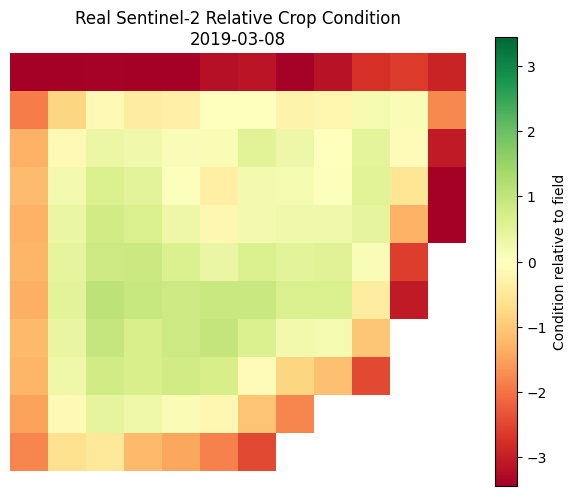

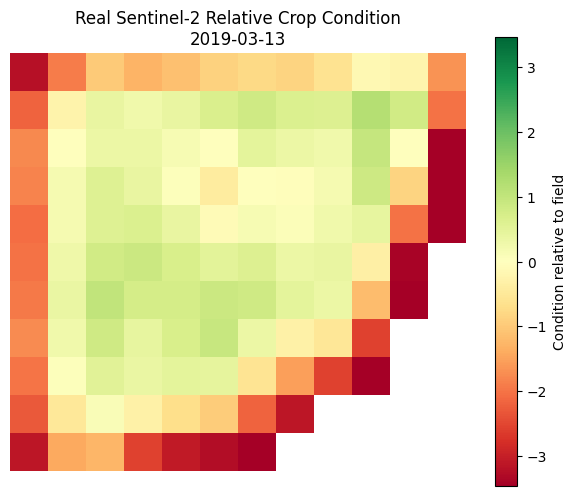

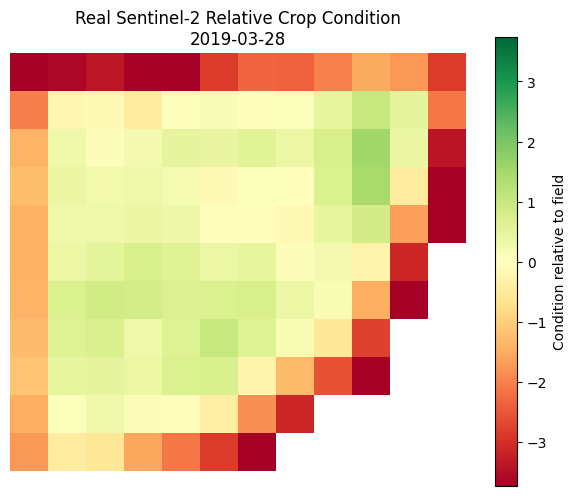

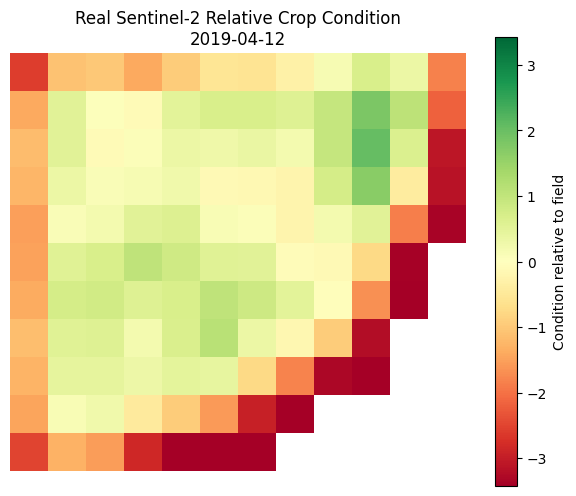

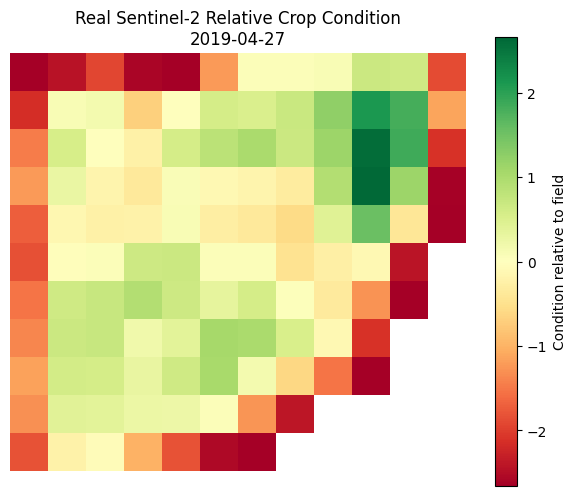

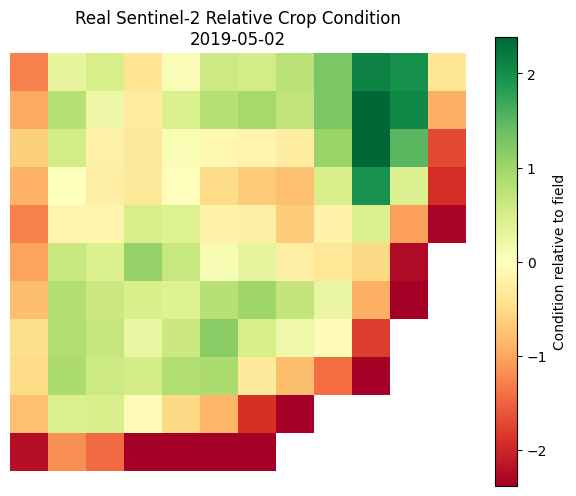

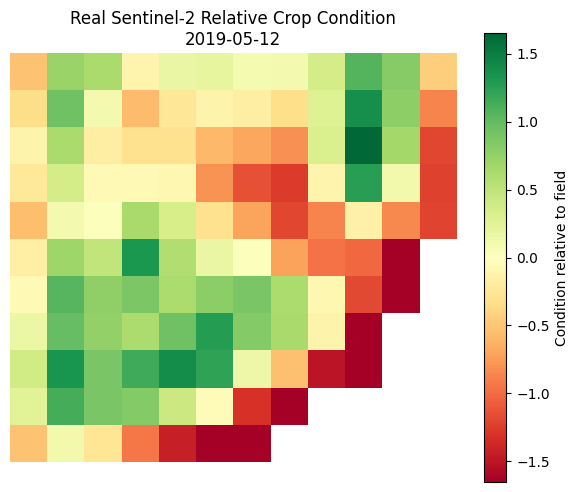

In [18]:
# ============================================================
# Step 18 — Map REAL Sentinel-2 relative crop condition
# Check whether weak areas persist / expand spatially
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Dates most useful around our ground measurements
MAP_DATES = [
    "2019-03-08",
    "2019-03-13",
    "2019-03-28",
    "2019-04-12",
    "2019-04-27",
    "2019-05-02",
    "2019-05-12"
]

for date_str in MAP_DATES:

    date = pd.Timestamp(date_str)

    subset = pixel_anomaly[
        pixel_anomaly["Date"] == date
    ]

    condition_map = np.full(
        ref20_shape,
        np.nan
    )

    for _, row in subset.iterrows():
        condition_map[
            int(row["Row"]),
            int(row["Col"])
        ] = row["Condition_score"]

    # Keep only manually selected AOI
    condition_map[~manual_mask20] = np.nan

    plt.figure(figsize=(6, 5))

    vmax = max(
        abs(np.nanpercentile(condition_map, 5)),
        abs(np.nanpercentile(condition_map, 95))
    )

    img = plt.imshow(
        condition_map,
        cmap="RdYlGn",
        vmin=-vmax,
        vmax=vmax
    )

    plt.colorbar(
        img,
        label="Condition relative to field"
    )

    plt.title(
        f"Real Sentinel-2 Relative Crop Condition\n{date_str}"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

Original 20 m pixels: 117
Interior pixels retained: 75
Boundary pixels removed: 42


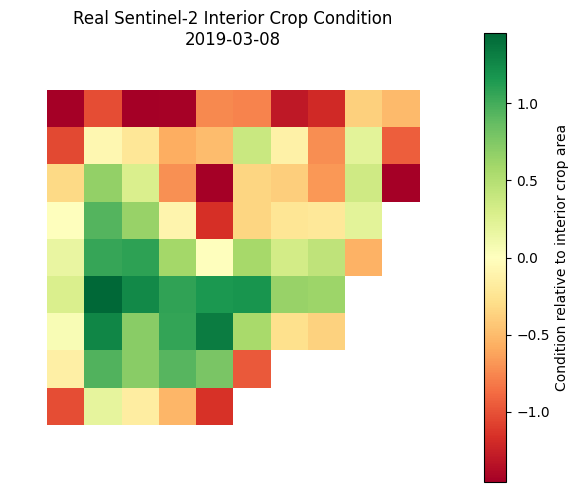

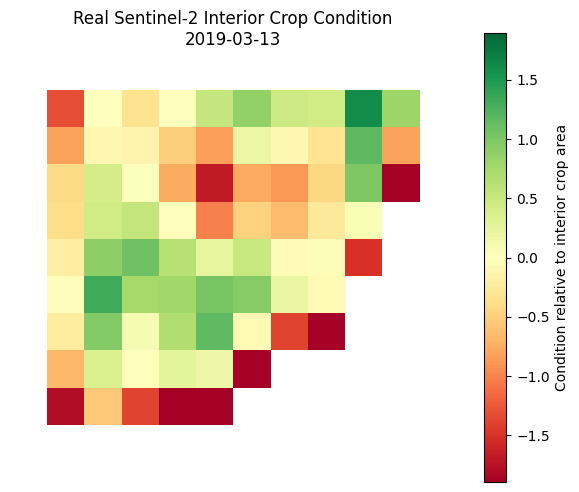

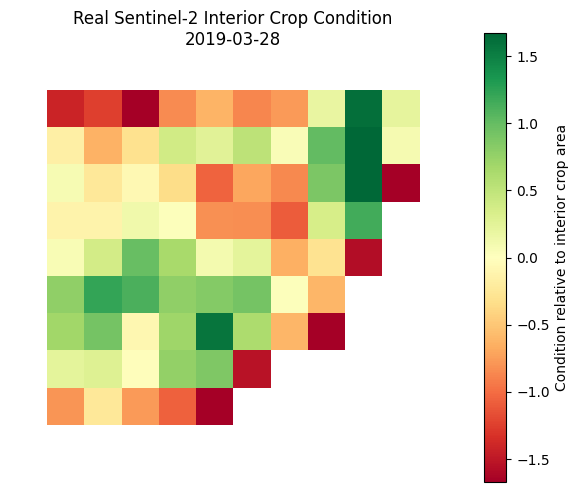

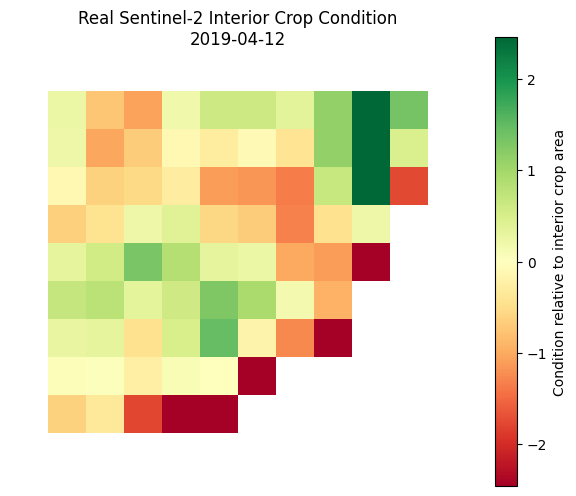

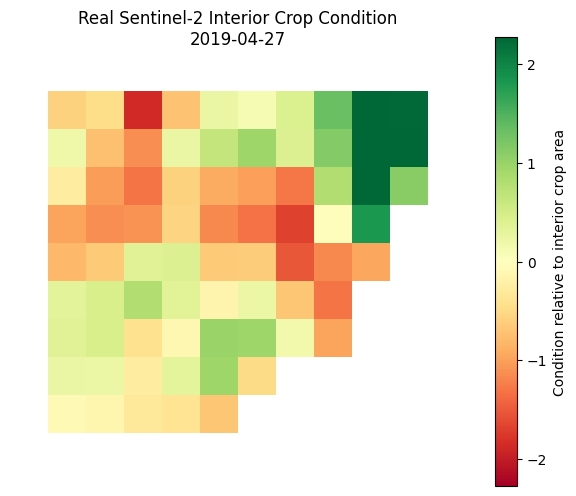

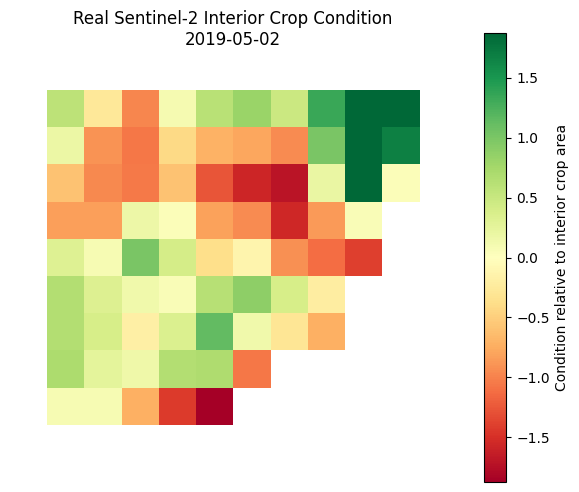

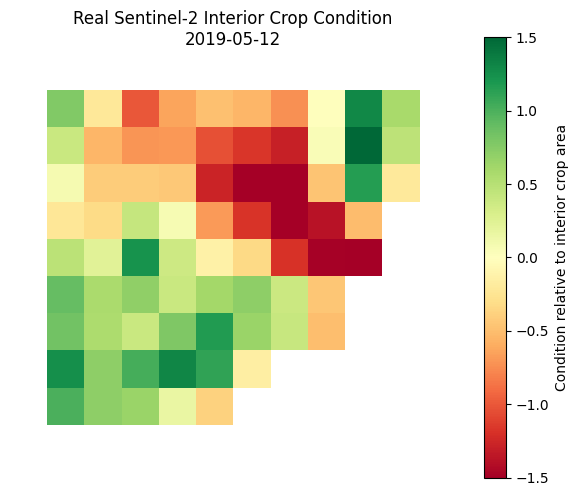

In [19]:
# ============================================================
# Step 19 — Remove AOI boundary / mixed pixels
# Keep only interior Sentinel-2 pixels
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import binary_erosion

# Remove one 20 m pixel around the AOI boundary
interior_mask20 = binary_erosion(
    manual_mask20,
    structure=np.ones((3, 3)),
    iterations=1
)

print("Original 20 m pixels:", manual_mask20.sum())
print("Interior pixels retained:", interior_mask20.sum())
print("Boundary pixels removed:",
      manual_mask20.sum() - interior_mask20.sum())


# ------------------------------------------------------------
# Recalculate relative condition using INTERIOR pixels only
# ------------------------------------------------------------

interior_ts = pixel_ts[
    pixel_ts.apply(
        lambda r: interior_mask20[int(r["Row"]), int(r["Col"])],
        axis=1
    )
].copy()


def robust_z(series):
    median = np.nanmedian(series)
    mad = np.nanmedian(np.abs(series - median))
    scale = 1.4826 * mad

    if scale == 0 or not np.isfinite(scale):
        return pd.Series(np.zeros(len(series)), index=series.index)

    return (series - median) / scale


for index_name in ["NDVI", "NDRE", "NDMI"]:

    interior_ts[f"{index_name}_relative"] = (
        interior_ts
        .groupby("Date")[index_name]
        .transform(robust_z)
    )


interior_ts["Condition_score"] = (
    interior_ts["NDVI_relative"]
    + interior_ts["NDRE_relative"]
    + interior_ts["NDMI_relative"]
) / 3


# ------------------------------------------------------------
# Show interior condition maps
# ------------------------------------------------------------

MAP_DATES = [
    "2019-03-08",
    "2019-03-13",
    "2019-03-28",
    "2019-04-12",
    "2019-04-27",
    "2019-05-02",
    "2019-05-12"
]

for date_str in MAP_DATES:

    subset = interior_ts[
        interior_ts["Date"] == pd.Timestamp(date_str)
    ]

    condition_map = np.full(ref20_shape, np.nan)

    for _, row in subset.iterrows():
        condition_map[
            int(row["Row"]),
            int(row["Col"])
        ] = row["Condition_score"]

    plt.figure(figsize=(6, 5))

    vmax = max(
        abs(np.nanpercentile(condition_map, 5)),
        abs(np.nanpercentile(condition_map, 95))
    )

    plt.imshow(
        condition_map,
        cmap="RdYlGn",
        vmin=-vmax,
        vmax=vmax
    )

    plt.colorbar(label="Condition relative to interior crop area")

    plt.title(
        f"Real Sentinel-2 Interior Crop Condition\n{date_str}"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

Frozen relative-condition threshold: -1.276

REAL SENTINEL-2 SPATIAL DETERIORATION SUMMARY


,Date,At_risk_pixels,At_risk_area_ha,Persistent_pixels,New_at_risk_pixels,New_adjacent_to_previous_%
0,2019-02-06,7,0.28,NaN,NaN,NaN
1,2019-02-16,5,0.20,4.0,1.0,0.0
2,2019-02-21,7,0.28,5.0,2.0,100.0
3,2019-02-26,7,0.28,5.0,2.0,50.0
4,2019-03-03,8,0.32,4.0,4.0,0.0
5,2019-03-08,6,0.24,3.0,3.0,0.0
6,2019-03-13,11,0.44,3.0,8.0,0.0
7,2019-03-18,6,0.24,5.0,1.0,0.0
8,2019-03-23,11,0.44,3.0,8.0,50.0
9,2019-03-28,7,0.28,5.0,2.0,0.0


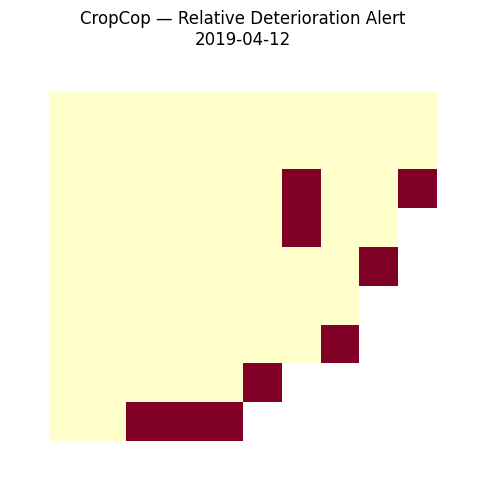

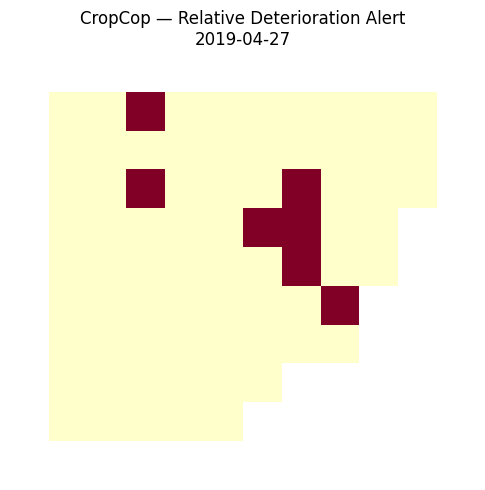

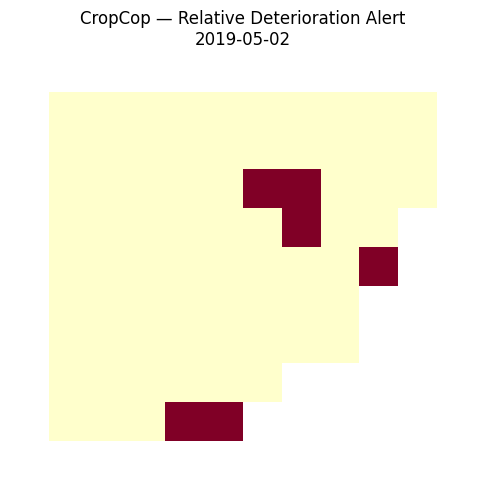

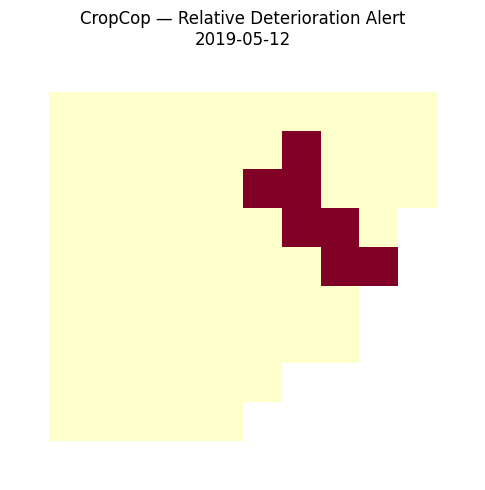

In [20]:
# ============================================================
# Step 20 — Quantify spatial deterioration / expansion
# REAL Sentinel-2 only
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import binary_dilation

# ------------------------------------------------------------
# 1. Establish threshold using EARLY-SEASON data only
#    (through 28 March)
# ------------------------------------------------------------

baseline = interior_ts[
    interior_ts["Date"] <= pd.Timestamp("2019-03-28")
]

# Worst 10% of early-season relative crop condition
RISK_THRESHOLD = np.nanpercentile(
    baseline["Condition_score"],
    10
)

print(
    "Frozen relative-condition threshold:",
    round(RISK_THRESHOLD, 3)
)

# ------------------------------------------------------------
# 2. Build low-condition masks for every date
# ------------------------------------------------------------

dates = sorted(interior_ts["Date"].unique())

risk_maps = {}
rows = []

previous_risk = None

for date in dates:

    subset = interior_ts[
        interior_ts["Date"] == date
    ]

    score_map = np.full(ref20_shape, np.nan)

    for _, row in subset.iterrows():
        score_map[
            int(row["Row"]),
            int(row["Col"])
        ] = row["Condition_score"]

    risk = (
        (score_map <= RISK_THRESHOLD)
        & interior_mask20
    )

    risk_maps[pd.Timestamp(date)] = risk

    n_risk = risk.sum()

    persistent = np.nan
    new_risk = np.nan
    adjacent_new = np.nan

    if previous_risk is not None:

        persistent_mask = risk & previous_risk
        new_mask = risk & (~previous_risk)

        persistent = persistent_mask.sum()
        new_risk = new_mask.sum()

        # 8-neighbour area surrounding previous weak pixels
        neighbour_zone = binary_dilation(
            previous_risk,
            structure=np.ones((3, 3))
        )

        if new_risk > 0:
            adjacent_new = (
                new_mask & neighbour_zone
            ).sum() / new_risk * 100

    rows.append({
        "Date": pd.Timestamp(date),
        "At_risk_pixels": n_risk,
        "At_risk_area_ha": n_risk * 0.04,
        "Persistent_pixels": persistent,
        "New_at_risk_pixels": new_risk,
        "New_adjacent_to_previous_%": adjacent_new
    })

    previous_risk = risk.copy()


expansion_summary = pd.DataFrame(rows)

print("\nREAL SENTINEL-2 SPATIAL DETERIORATION SUMMARY")
display(expansion_summary.round(2))


# ------------------------------------------------------------
# 3. Plot late-season risk maps with SAME meaning
# ------------------------------------------------------------

for date_str in [
    "2019-04-12",
    "2019-04-27",
    "2019-05-02",
    "2019-05-12"
]:

    date = pd.Timestamp(date_str)
    risk = risk_maps[date]

    display_map = np.full(ref20_shape, np.nan)
    display_map[interior_mask20] = 0
    display_map[risk] = 1

    plt.figure(figsize=(6, 5))

    plt.imshow(
        display_map,
        cmap="YlOrRd",
        vmin=0,
        vmax=1
    )

    plt.title(
        f"CropCop — Relative Deterioration Alert\n{date_str}"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

CROPCOP REAL SENTINEL-2 HINDCAST
----------------------------------
Training transitions: 825
Held-out pixels: 75

Forecast:
May 2 → May 12, 2019

Actual May 12 at-risk pixels: 7

ROC-AUC: 0.771
PR-AUC: 0.324
Baseline PR-AUC: 0.093
Brier score: 0.163

Top-8 predicted pixels:
Correctly identified: 3
Recall: 42.9%
Precision: 37.5%


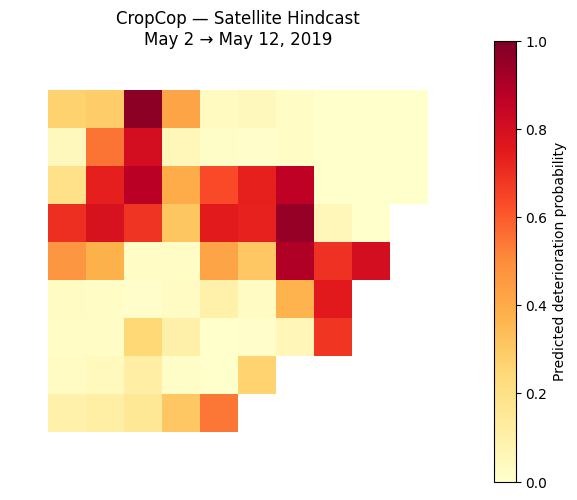

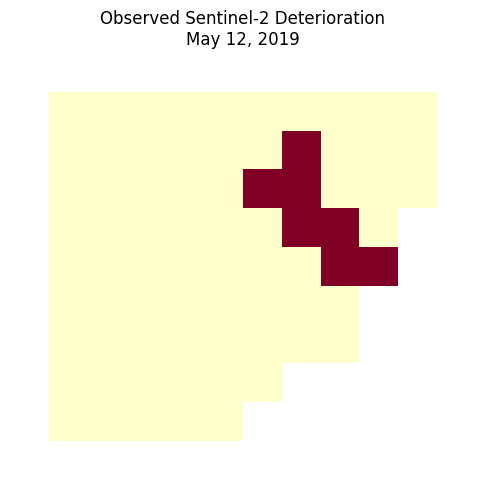

In [21]:
# ============================================================
# Step 21 — CropCop REAL Sentinel-2 hindcast
#
# Train on historical transitions only.
# Use May 2 information to predict May 12 deterioration.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import convolve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# ------------------------------------------------------------
# 1. Build condition-score maps for every date
# ------------------------------------------------------------

date_list = [
    pd.Timestamp(d)
    for d in sorted(interior_ts["Date"].unique())
]

score_maps = {}

for date in date_list:

    arr = np.full(ref20_shape, np.nan)

    subset = interior_ts[
        interior_ts["Date"] == date
    ]

    for _, row in subset.iterrows():
        arr[int(row["Row"]), int(row["Col"])] = row["Condition_score"]

    score_maps[date] = arr


# ------------------------------------------------------------
# 2. Build transition dataset
#
# Features available at CURRENT date:
# - current relative condition
# - recent condition trend
# - whether pixel is already weak
# - fraction of neighbouring pixels currently weak
# - time until next observation
#
# Target:
# - weak/not weak at NEXT Sentinel-2 observation
# ------------------------------------------------------------

kernel = np.ones((3, 3), dtype=float)
kernel[1, 1] = 0

available_neighbours = convolve(
    interior_mask20.astype(float),
    kernel,
    mode="constant",
    cval=0
)

transition_rows = []

# Need previous date for trend and next date for target
for i in range(1, len(date_list) - 1):

    previous_date = date_list[i - 1]
    current_date = date_list[i]
    next_date = date_list[i + 1]

    previous_score = score_maps[previous_date]
    current_score = score_maps[current_date]

    current_risk = risk_maps[current_date]
    next_risk = risk_maps[next_date]

    days_previous = (current_date - previous_date).days
    days_next = (next_date - current_date).days

    trend_per_day = (
        current_score - previous_score
    ) / days_previous

    neighbour_risk_count = convolve(
        current_risk.astype(float),
        kernel,
        mode="constant",
        cval=0
    )

    neighbour_risk_fraction = np.divide(
        neighbour_risk_count,
        available_neighbours,
        out=np.zeros_like(neighbour_risk_count),
        where=available_neighbours > 0
    )

    for r, c in zip(*np.where(interior_mask20)):

        transition_rows.append({
            "Current_date": current_date,
            "Next_date": next_date,
            "Row": r,
            "Col": c,

            "Condition_now": current_score[r, c],
            "Trend_per_day": trend_per_day[r, c],
            "At_risk_now": int(current_risk[r, c]),
            "Neighbour_risk_fraction":
                neighbour_risk_fraction[r, c],
            "Forecast_horizon_days": days_next,

            "At_risk_next": int(next_risk[r, c])
        })


transitions = pd.DataFrame(transition_rows)


# ------------------------------------------------------------
# 3. STRICT temporal holdout
#
# Train only on transitions before May 2.
# May 2 → May 12 is never shown during training.
# ------------------------------------------------------------

TEST_DATE = pd.Timestamp("2019-05-02")

train = transitions[
    transitions["Current_date"] < TEST_DATE
].copy()

test = transitions[
    transitions["Current_date"] == TEST_DATE
].copy()

features = [
    "Condition_now",
    "Trend_per_day",
    "At_risk_now",
    "Neighbour_risk_fraction",
    "Forecast_horizon_days"
]

X_train = train[features]
y_train = train["At_risk_next"]

X_test = test[features]
y_test = test["At_risk_next"]


# ------------------------------------------------------------
# 4. Simple interpretable prediction model
# ------------------------------------------------------------

model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        random_state=813,
        max_iter=1000
    ))
])

model.fit(X_train, y_train)

probability = model.predict_proba(X_test)[:, 1]


# ------------------------------------------------------------
# 5. Evaluate completely unseen May 12 outcome
# ------------------------------------------------------------

roc_auc = roc_auc_score(y_test, probability)
pr_auc = average_precision_score(y_test, probability)
brier = brier_score_loss(y_test, probability)

# Top 10% predicted-risk pixels
k = int(np.ceil(len(test) * 0.10))

top_indices = np.argsort(-probability)[:k]

hits = y_test.iloc[top_indices].sum()

actual_risk_pixels = int(y_test.sum())

recall_top10 = (
    hits / actual_risk_pixels
    if actual_risk_pixels > 0
    else np.nan
)

precision_top10 = hits / k


print("CROPCOP REAL SENTINEL-2 HINDCAST")
print("----------------------------------")
print("Training transitions:", len(train))
print("Held-out pixels:", len(test))
print()
print("Forecast:")
print("May 2 → May 12, 2019")
print()
print("Actual May 12 at-risk pixels:", actual_risk_pixels)
print()
print(f"ROC-AUC: {roc_auc:.3f}")
print(f"PR-AUC: {pr_auc:.3f}")
print(f"Baseline PR-AUC: {y_test.mean():.3f}")
print(f"Brier score: {brier:.3f}")
print()
print(f"Top-{k} predicted pixels:")
print("Correctly identified:", int(hits))
print(f"Recall: {recall_top10:.1%}")
print(f"Precision: {precision_top10:.1%}")


# ------------------------------------------------------------
# 6. Predicted May 12 risk map
# ------------------------------------------------------------

prediction_map = np.full(ref20_shape, np.nan)
truth_map = np.full(ref20_shape, np.nan)

for (_, row), prob in zip(test.iterrows(), probability):

    r = int(row["Row"])
    c = int(row["Col"])

    prediction_map[r, c] = prob
    truth_map[r, c] = row["At_risk_next"]


plt.figure(figsize=(6, 5))

plt.imshow(
    prediction_map,
    cmap="YlOrRd",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Predicted deterioration probability")

plt.title(
    "CropCop — Satellite Hindcast\n"
    "May 2 → May 12, 2019"
)

plt.axis("off")
plt.tight_layout()
plt.show()


plt.figure(figsize=(6, 5))

plt.imshow(
    truth_map,
    cmap="YlOrRd",
    vmin=0,
    vmax=1
)

plt.title(
    "Observed Sentinel-2 Deterioration\n"
    "May 12, 2019"
)

plt.axis("off")
plt.tight_layout()
plt.show()

## Final spatial-progression evaluation

The earlier Sentinel-2 analysis establishes the temporal feature pipeline.

For the final CropCop progression test, a stricter operational target is used:

**Among pixels that are not currently weak, which pixels become weak at the next satellite observation?**

This removes already-weak pixels from the prediction target and focuses the evaluation
on the emergence of new spatial crop-condition weakness.

In [22]:
# ============================================================
# Step 21E — Audit newly emerging weak areas
#
# Question:
# Among pixels that are NOT currently weak,
# how many become weak at the next Sentinel-2 observation?
# ============================================================

import numpy as np
import pandas as pd


emergence = transitions.copy()


# ------------------------------------------------------------
# 1. Define newly emerging weak areas
# ------------------------------------------------------------

emergence["Newly_weak"] = (
    (emergence["At_risk_now"] == 0)
    &
    (emergence["At_risk_next"] == 1)
).astype(int)


emergence["Persistent_weak"] = (
    (emergence["At_risk_now"] == 1)
    &
    (emergence["At_risk_next"] == 1)
).astype(int)


emergence["Recovered"] = (
    (emergence["At_risk_now"] == 1)
    &
    (emergence["At_risk_next"] == 0)
).astype(int)


# ------------------------------------------------------------
# 2. Use only the four evaluation origins
# ------------------------------------------------------------

FORECAST_ORIGINS = [
    pd.Timestamp("2019-03-28"),
    pd.Timestamp("2019-04-12"),
    pd.Timestamp("2019-04-27"),
    pd.Timestamp("2019-05-02")
]

eval_emergence = emergence[
    emergence["Current_date"].isin(
        FORECAST_ORIGINS
    )
].copy()


# ------------------------------------------------------------
# 3. Summarise each transition
# ------------------------------------------------------------

rows = []

for (current_date, next_date), g in (
    eval_emergence
    .groupby(
        ["Current_date", "Next_date"]
    )
):

    currently_not_weak = (
        g["At_risk_now"] == 0
    ).sum()

    newly_weak = (
        g["Newly_weak"].sum()
    )

    rows.append({

        "Current_date":
            current_date.date(),

        "Next_date":
            next_date.date(),

        "Total_pixels":
            len(g),

        "Currently_not_weak":
            currently_not_weak,

        "Newly_weak_next":
            newly_weak,

        "New_weak_rate":
            (
                newly_weak
                / currently_not_weak
                if currently_not_weak > 0
                else np.nan
            ),

        "Persistent_weak":
            g["Persistent_weak"].sum(),

        "Recovered":
            g["Recovered"].sum()
    })


emergence_audit = pd.DataFrame(
    rows
)


print(
    "REAL SENTINEL-2 — NEW WEAK-AREA EMERGENCE\n"
)

display(
    emergence_audit.round(3)
)


print(
    "\nTotal newly weak pixel-events:",
    int(
        eval_emergence[
            "Newly_weak"
        ].sum()
    )
)

REAL SENTINEL-2 — NEW WEAK-AREA EMERGENCE



,Current_date,Next_date,Total_pixels,Currently_not_weak,Newly_weak_next,New_weak_rate,Persistent_weak,Recovered
0,2019-03-28,2019-04-12,75,68,4,0.059,5,2
1,2019-04-12,2019-04-27,75,66,5,0.076,2,7
2,2019-04-27,2019-05-02,75,68,4,0.059,2,5
3,2019-05-02,2019-05-12,75,69,3,0.043,4,2



Total newly weak pixel-events: 16


In [23]:
# ============================================================
# Step 21F — Predict NEW weak-area emergence
#
# REAL Sentinel-2
#
# Question:
# Among pixels that are NOT currently weak,
# can we predict which ones become weak at the next observation?
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)


# ------------------------------------------------------------
# 1. Keep only pixels that are NOT weak at the current date
# ------------------------------------------------------------

emergence_candidates = emergence[
    emergence["At_risk_now"] == 0
].copy()


# ------------------------------------------------------------
# 2. Features
#
# At_risk_now is excluded because every candidate = 0.
# ------------------------------------------------------------

EMERGENCE_FEATURES = [
    "Condition_now",
    "Trend_per_day",
    "Neighbour_risk_fraction",
    "Forecast_horizon_days"
]


FORECAST_ORIGINS = [
    pd.Timestamp("2019-03-28"),
    pd.Timestamp("2019-04-12"),
    pd.Timestamp("2019-04-27"),
    pd.Timestamp("2019-05-02")
]


all_rows = []
summary_rows = []


# ------------------------------------------------------------
# 3. Rolling temporal evaluation
# ------------------------------------------------------------

for origin in FORECAST_ORIGINS:

    train = emergence_candidates[
        emergence_candidates["Current_date"] < origin
    ].copy()

    test = emergence_candidates[
        emergence_candidates["Current_date"] == origin
    ].copy()


    print(
        f"\nForecast origin: {origin.date()}"
    )

    print(
        "Training observations:",
        len(train),
        "| training positives:",
        int(train["Newly_weak"].sum())
    )

    print(
        "Test observations:",
        len(test),
        "| test positives:",
        int(test["Newly_weak"].sum())
    )


    # Need both classes to train
    if train["Newly_weak"].nunique() < 2:
        print(
            "Skipped: training data contain only one class."
        )
        continue


    X_train = train[
        EMERGENCE_FEATURES
    ]

    y_train = train[
        "Newly_weak"
    ]


    X_test = test[
        EMERGENCE_FEATURES
    ]

    y_test = test[
        "Newly_weak"
    ].to_numpy()


    # --------------------------------------------------------
    # ML model
    # --------------------------------------------------------

    model = Pipeline([

        (
            "scale",
            StandardScaler()
        ),

        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                random_state=813,
                max_iter=1000
            )
        )
    ])


    model.fit(
        X_train,
        y_train
    )


    ml_score = model.predict_proba(
        X_test
    )[:, 1]


    # --------------------------------------------------------
    # Simple baselines
    #
    # Lower current condition = greater risk.
    # More negative trend = greater worsening.
    # Higher neighbour weak fraction = greater spatial risk.
    # --------------------------------------------------------

    condition_score = (
        -test["Condition_now"]
        .to_numpy(dtype=float)
    )

    trend_score = (
        -test["Trend_per_day"]
        .to_numpy(dtype=float)
    )

    neighbour_score = (
        test["Neighbour_risk_fraction"]
        .to_numpy(dtype=float)
    )


    methods = {

        "ML":
            ml_score,

        "Condition_only":
            condition_score,

        "Trend_only":
            trend_score,

        "Neighbour_only":
            neighbour_score
    }


    # --------------------------------------------------------
    # Evaluate each method
    # --------------------------------------------------------

    for method, score in methods.items():

        pr_auc = average_precision_score(
            y_test,
            score
        )

        roc_auc = roc_auc_score(
            y_test,
            score
        )


        # Top 10% inspection budget
        k = max(
            1,
            int(
                np.ceil(
                    0.10 * len(test)
                )
            )
        )

        ranking = np.argsort(
            -score
        )

        top = ranking[:k]

        hits = int(
            y_test[top].sum()
        )


        summary_rows.append({

            "Current_date":
                origin.date(),

            "Method":
                method,

            "Candidates":
                len(test),

            "Newly_weak":
                int(y_test.sum()),

            "PR_AUC":
                pr_auc,

            "ROC_AUC":
                roc_auc,

            "Top10_n":
                k,

            "Top10_hits":
                hits,

            "Top10_recall":
                (
                    hits / y_test.sum()
                    if y_test.sum() > 0
                    else np.nan
                )
        })


    # --------------------------------------------------------
    # Save pixel-level results
    # --------------------------------------------------------

    for i, (_, row) in enumerate(
        test.iterrows()
    ):

        all_rows.append({

            "Current_date":
                row["Current_date"],

            "Next_date":
                row["Next_date"],

            "Row":
                int(row["Row"]),

            "Col":
                int(row["Col"]),

            "Newly_weak":
                int(row["Newly_weak"]),

            "Condition_now":
                row["Condition_now"],

            "Trend_per_day":
                row["Trend_per_day"],

            "Neighbour_risk_fraction":
                row["Neighbour_risk_fraction"],

            "ML":
                ml_score[i],

            "Condition_only":
                condition_score[i],

            "Trend_only":
                trend_score[i],

            "Neighbour_only":
                neighbour_score[i]
        })


emergence_predictions = pd.DataFrame(
    all_rows
)

emergence_summary = pd.DataFrame(
    summary_rows
)


# ------------------------------------------------------------
# 4. Results
# ------------------------------------------------------------

print(
    "\n\nNEW WEAK-AREA EMERGENCE — "
    "ROLLING FORECAST RESULTS\n"
)

display(
    emergence_summary.round(3)
)


print(
    "\nMEAN ACROSS FORECAST ORIGINS\n"
)

mean_results = (
    emergence_summary
    .groupby("Method")[
        [
            "PR_AUC",
            "ROC_AUC",
            "Top10_recall"
        ]
    ]
    .mean()
    .sort_values(
        "PR_AUC",
        ascending=False
    )
)

display(
    mean_results.round(3)
)


Forecast origin: 2019-03-28
Training observations: 539 | training positives: 30
Test observations: 68 | test positives: 4

Forecast origin: 2019-04-12
Training observations: 607 | training positives: 34
Test observations: 66 | test positives: 5

Forecast origin: 2019-04-27
Training observations: 673 | training positives: 39
Test observations: 68 | test positives: 4

Forecast origin: 2019-05-02
Training observations: 741 | training positives: 43
Test observations: 69 | test positives: 3


NEW WEAK-AREA EMERGENCE — ROLLING FORECAST RESULTS



,Current_date,Method,Candidates,Newly_weak,PR_AUC,ROC_AUC,Top10_n,Top10_hits,Top10_recall
0,2019-03-28,ML,68,4,0.646,0.930,7,2,0.500
1,2019-03-28,Condition_only,68,4,0.508,0.953,7,3,0.750
2,2019-03-28,Trend_only,68,4,0.072,0.355,7,0,0.000
3,2019-03-28,Neighbour_only,68,4,0.069,0.484,7,0,0.000
4,2019-04-12,ML,66,5,0.405,0.856,7,2,0.400
5,2019-04-12,Condition_only,66,5,0.307,0.895,7,2,0.400
6,2019-04-12,Trend_only,66,5,0.092,0.515,7,0,0.000
7,2019-04-12,Neighbour_only,66,5,0.125,0.638,7,1,0.200
8,2019-04-27,ML,68,4,0.676,0.953,7,3,0.750
9,2019-04-27,Condition_only,68,4,0.171,0.809,7,1,0.250



MEAN ACROSS FORECAST ORIGINS



,PR_AUC,ROC_AUC,Top10_recall
Method,,,
ML,0.447,0.805,0.412
Condition_only,0.330,0.894,0.433
Neighbour_only,0.197,0.679,0.362
Trend_only,0.104,0.455,0.167


In [24]:
# ============================================================
# Step 21G — Spatial-block bootstrap for NEW weak-area emergence
#
# Compare ML against simple baselines while accounting for
# spatial dependence between nearby Sentinel-2 pixels.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import average_precision_score


# ------------------------------------------------------------
# 1. Create ~40 m × 40 m spatial blocks
# Each Sentinel-2 grid cell here is 20 m.
# ------------------------------------------------------------

boot_data = emergence_predictions.copy()

boot_data["Block_row"] = (
    boot_data["Row"] // 2
)

boot_data["Block_col"] = (
    boot_data["Col"] // 2
)

boot_data["Block"] = (
    boot_data["Block_row"].astype(str)
    + "_"
    + boot_data["Block_col"].astype(str)
)


blocks = (
    boot_data[
        ["Block"]
    ]
    .drop_duplicates()["Block"]
    .to_numpy()
)


print(
    "Spatial blocks:",
    len(blocks)
)


# ------------------------------------------------------------
# 2. Observed mean PR-AUC across the four dates
# ------------------------------------------------------------

METHODS = [
    "ML",
    "Condition_only",
    "Neighbour_only",
    "Trend_only"
]


def mean_date_pr_auc(df, method):

    scores = []

    for date, g in df.groupby(
        "Current_date"
    ):

        y = g["Newly_weak"].to_numpy()

        # PR-AUC is only meaningful if both classes exist
        if (
            y.sum() == 0
            or y.sum() == len(y)
        ):
            continue

        scores.append(
            average_precision_score(
                y,
                g[method].to_numpy(dtype=float)
            )
        )

    if len(scores) == 0:
        return np.nan

    return np.mean(scores)


observed = {
    method:
        mean_date_pr_auc(
            boot_data,
            method
        )
    for method in METHODS
}


print(
    "\nObserved mean PR-AUC:"
)

for method, value in observed.items():

    print(
        f"{method:16s}: {value:.3f}"
    )


# ------------------------------------------------------------
# 3. Spatial-block bootstrap
# ------------------------------------------------------------

N_BOOT = 5000
rng = np.random.default_rng(813)

comparisons = {
    "ML - Condition_only": [],
    "ML - Neighbour_only": [],
    "ML - Trend_only": []
}

valid_bootstraps = 0


for _ in range(N_BOOT):

    sampled_blocks = rng.choice(
        blocks,
        size=len(blocks),
        replace=True
    )

    pieces = []

    for draw_id, block in enumerate(
        sampled_blocks
    ):

        part = boot_data[
            boot_data["Block"] == block
        ].copy()

        part["Bootstrap_block"] = (
            draw_id
        )

        pieces.append(part)


    boot = pd.concat(
        pieces,
        ignore_index=True
    )


    # Calculate each method's mean PR-AUC
    boot_scores = {}

    for method in METHODS:

        score = mean_date_pr_auc(
            boot,
            method
        )

        boot_scores[method] = score


    # Require all four methods to be valid
    if any(
        np.isnan(v)
        for v in boot_scores.values()
    ):
        continue


    valid_bootstraps += 1


    comparisons[
        "ML - Condition_only"
    ].append(
        boot_scores["ML"]
        - boot_scores["Condition_only"]
    )

    comparisons[
        "ML - Neighbour_only"
    ].append(
        boot_scores["ML"]
        - boot_scores["Neighbour_only"]
    )

    comparisons[
        "ML - Trend_only"
    ].append(
        boot_scores["ML"]
        - boot_scores["Trend_only"]
    )


# ------------------------------------------------------------
# 4. Confidence intervals
# ------------------------------------------------------------

rows = []

for name, values in comparisons.items():

    values = np.asarray(values)

    baseline = name.replace(
        "ML - ",
        ""
    )

    observed_difference = (
        observed["ML"]
        - observed[baseline]
    )

    rows.append({

        "Comparison":
            name,

        "Observed_PR_AUC_difference":
            observed_difference,

        "Bootstrap_mean":
            values.mean(),

        "95% CI low":
            np.percentile(
                values,
                2.5
            ),

        "95% CI high":
            np.percentile(
                values,
                97.5
            )
    })


emergence_bootstrap = pd.DataFrame(
    rows
)


print(
    "\nNEW-AREA EMERGENCE — "
    "SPATIAL-BLOCK BOOTSTRAP\n"
)

display(
    emergence_bootstrap.round(3)
)

print(
    "\nRequested bootstraps:",
    N_BOOT
)

print(
    "Valid bootstraps:",
    valid_bootstraps
)

Spatial blocks: 26

Observed mean PR-AUC:
ML              : 0.447
Condition_only  : 0.330
Neighbour_only  : 0.197
Trend_only      : 0.104

NEW-AREA EMERGENCE — SPATIAL-BLOCK BOOTSTRAP



,Comparison,Observed_PR_AUC_difference,Bootstrap_mean,95% CI low,95% CI high
0,ML - Condition_only,0.117,0.080,-0.226,0.437
1,ML - Neighbour_only,0.249,0.242,-0.134,0.669
2,ML - Trend_only,0.342,0.349,0.049,0.711



Requested bootstraps: 5000
Valid bootstraps: 4999


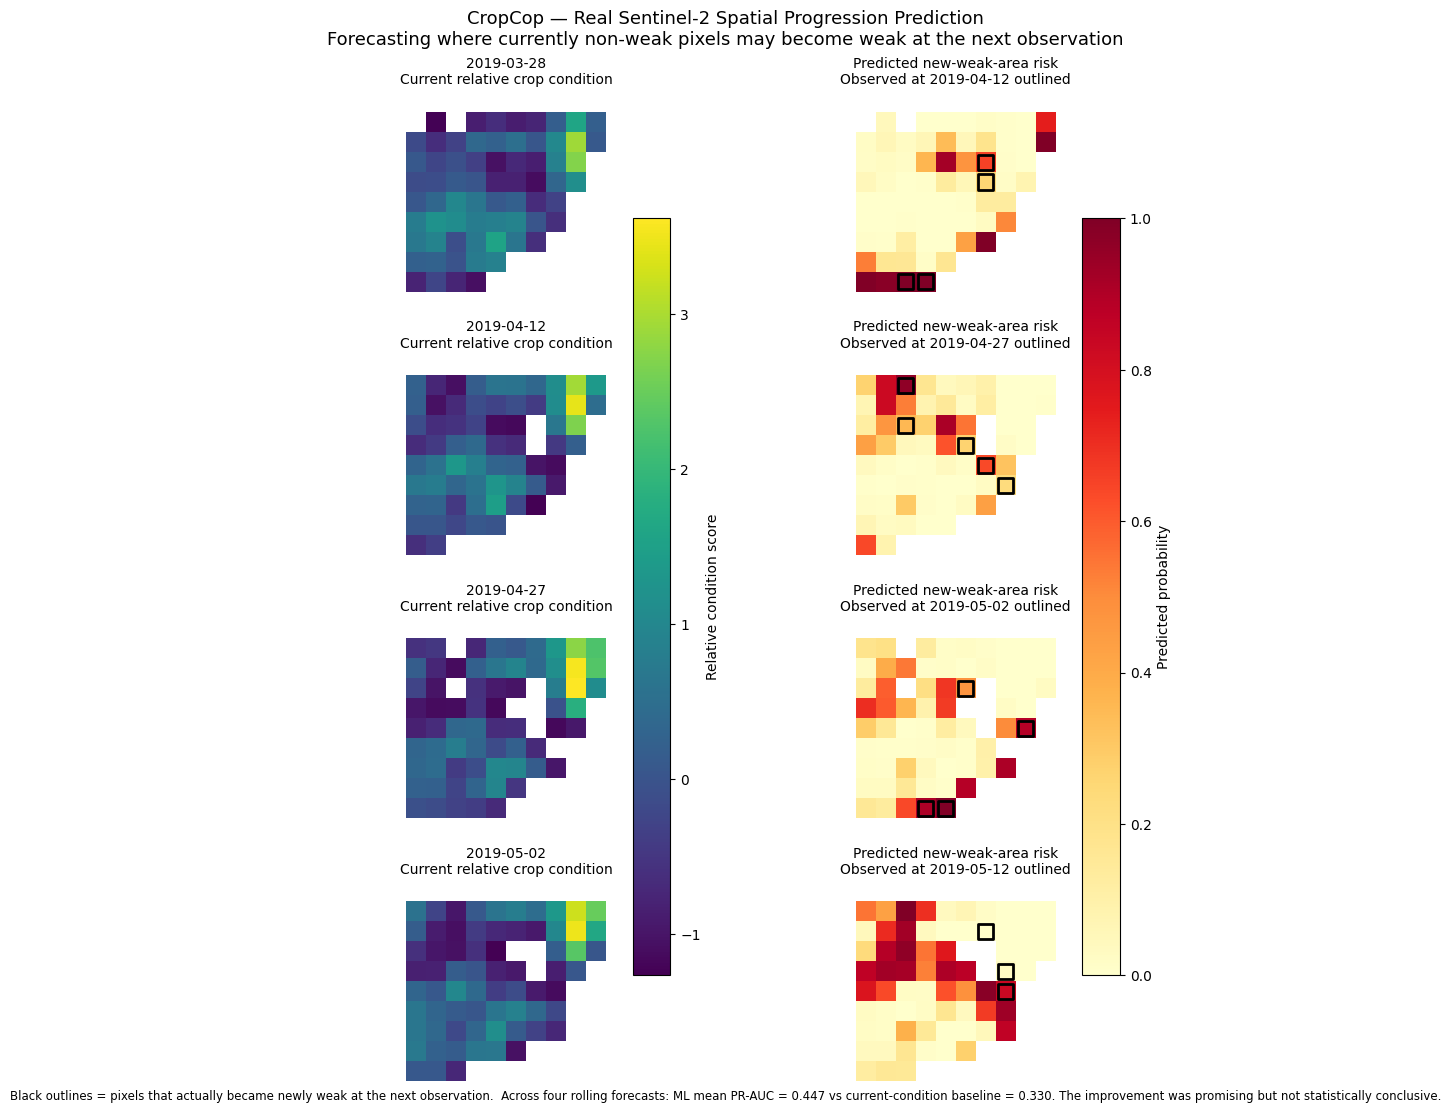

In [25]:
# ============================================================
# Step 21H — FINAL judge-facing spatial progression figure
# Real Sentinel-2
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


dates = sorted(
    emergence_predictions["Current_date"].unique()
)


# ------------------------------------------------------------
# 1. Use one common condition scale across all dates
# ------------------------------------------------------------

condition_min = (
    emergence_predictions["Condition_now"]
    .min()
)

condition_max = (
    emergence_predictions["Condition_now"]
    .max()
)


# ------------------------------------------------------------
# 2. Create figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(dates),
    2,
    figsize=(9, 11),
    layout="constrained"
)


# ------------------------------------------------------------
# 3. Build each forecast row
# ------------------------------------------------------------

for row_i, current_date in enumerate(dates):

    g = emergence_predictions[
        emergence_predictions["Current_date"]
        == current_date
    ].copy()

    next_date = pd.Timestamp(
        g["Next_date"].iloc[0]
    ).date()


    # --------------------------------------------------------
    # Create empty maps
    # --------------------------------------------------------

    condition_map = np.full(
        ref20_shape,
        np.nan
    )

    prediction_map = np.full(
        ref20_shape,
        np.nan
    )


    rr = g["Row"].astype(int).to_numpy()
    cc = g["Col"].astype(int).to_numpy()


    condition_map[
        rr,
        cc
    ] = g[
        "Condition_now"
    ].to_numpy(dtype=float)


    prediction_map[
        rr,
        cc
    ] = g[
        "ML"
    ].to_numpy(dtype=float)


    # --------------------------------------------------------
    # Left panel:
    # current relative crop condition
    # --------------------------------------------------------

    im_condition = axes[row_i, 0].imshow(
        condition_map,
        cmap="viridis",
        vmin=condition_min,
        vmax=condition_max
    )

    axes[row_i, 0].set_title(
        f"{pd.Timestamp(current_date).date()}\n"
        "Current relative crop condition",
        fontsize=10
    )


    # --------------------------------------------------------
    # Right panel:
    # predicted new-weak-area risk
    # --------------------------------------------------------

    im_prediction = axes[row_i, 1].imshow(
        prediction_map,
        cmap="YlOrRd",
        vmin=0,
        vmax=1
    )


    # Pixels that actually became newly weak
    actual = g[
        g["Newly_weak"] == 1
    ]


    axes[row_i, 1].scatter(
        actual["Col"],
        actual["Row"],
        marker="s",
        s=120,
        facecolors="none",
        edgecolors="black",
        linewidths=2
    )


    axes[row_i, 1].set_title(
        "Predicted new-weak-area risk\n"
        f"Observed at {next_date} outlined",
        fontsize=10
    )


    # Remove axis ticks/frames
    for col_i in range(2):

        axes[row_i, col_i].axis(
            "off"
        )


# ------------------------------------------------------------
# 4. Shared colorbars
# ------------------------------------------------------------

cbar_condition = fig.colorbar(
    im_condition,
    ax=axes[:, 0],
    shrink=0.75,
    pad=0.02
)

cbar_condition.set_label(
    "Relative condition score"
)


cbar_prediction = fig.colorbar(
    im_prediction,
    ax=axes[:, 1],
    shrink=0.75,
    pad=0.02
)

cbar_prediction.set_label(
    "Predicted probability"
)


# ------------------------------------------------------------
# 5. Main title
# ------------------------------------------------------------

fig.suptitle(
    "CropCop — Real Sentinel-2 Spatial Progression Prediction\n"
    "Forecasting where currently non-weak pixels may become weak "
    "at the next observation",
    fontsize=13
)


# ------------------------------------------------------------
# 6. Evidence note
# ------------------------------------------------------------

fig.text(
    0.5,
    0.005,
    (
        "Black outlines = pixels that actually became newly weak "
        "at the next observation.  "
        "Across four rolling forecasts: ML mean PR-AUC = 0.447 "
        "vs current-condition baseline = 0.330. "
        "The improvement was promising but not statistically conclusive."
    ),
    ha="center",
    fontsize=8.5
)


plt.show()

### Real Sentinel-2 spatial-progression result

CropCop was evaluated using a real 14-date Sentinel-2 Level-2A time series over the
experimental field.

To test spatial progression, the model was asked a stricter question:

**Among pixels that are not currently weak, which ones are most likely to become weak
at the next satellite observation?**

Across four rolling forecast origins, 16 newly weak pixel-events were observed.

The ML model achieved:

- **Mean PR-AUC: 0.447**
- Current-condition baseline: **0.330**
- Neighbour-only baseline: **0.197**
- Trend-only baseline: **0.104**

The ML model therefore produced the highest observed mean PR-AUC and clearly
outperformed the simple trend baseline.

However, spatial-block bootstrap uncertainty was wide. The improvement over current
condition alone was **+0.117 PR-AUC**, with a 95% CI of **-0.226 to +0.437**.

Therefore, the PoC demonstrates a functioning real-satellite spatial-progression
prediction pipeline and promising next-observation risk ranking, but does not claim
statistically proven superiority over current crop condition alone.

The output is best interpreted as an **early-warning spatial risk map** showing where
crop-condition weakness may emerge next, rather than a validated biological
stress-spread forecast.

In [26]:
# ============================================================
# Diagnosis Step 1 — Inspect airborne + ground-truth datasets
# ============================================================

import pandas as pd

AGRONOMIC_FILE = DATA_DIR / "Crop_agronomic_data_wheat.xlsx"
AIRBORNE_FILE = DATA_DIR / "Crop_Reflectance_temp_from_Plane_Corrected.xlsx"

for label, path in {
    "GROUND TRUTH / AGRONOMIC": AGRONOMIC_FILE,
    "AIRBORNE HYPERSPECTRAL + THERMAL": AIRBORNE_FILE
}.items():

    print("\n" + "=" * 80)
    print(label)

    xls = pd.ExcelFile(path)

    print("Sheets:", xls.sheet_names)

    for sheet in xls.sheet_names:
        df = pd.read_excel(path, sheet_name=sheet)

        print(f"\nSheet: {sheet}")
        print("Shape:", df.shape)

        print("\nColumns:")
        for c in df.columns:
            print(" -", c)

        print("\nFirst 3 rows:")
        display(df.head(3))


GROUND TRUTH / AGRONOMIC
Sheets: ['Data', 'Read me']

Sheet: Data
Shape: (192, 19)

Columns:
 - Plot
 - Date
 - Year
 - FactorN
 - FactorW
 - Biomass kg ms /ha
 - Biom_N_Concentration %
 - Biom_Ncontent kg N/ha
 - Shoot_Biomass
 - Shoot_N_Concentration %
 - Shoot_Ncontent kg N/ha
 - Spikes_Biomass kg ms/ha
 - Spikes_N_Concentration %
 - Spikes_Ncontent kg N/ha
 - Yield kg ms/ha
 - Grain_N_Concentration %
 - Grain_Ncontent kg N/ha
 - NNI_ajusted
 - NNI_justes

First 3 rows:


,Plot,Date,Year,FactorN,FactorW,Biomass kg ms /ha,Biom_N_Concentration %,Biom_Ncontent kg N/ha,Shoot_Biomass,Shoot_N_Concentration %,Shoot_Ncontent kg N/ha,Spikes_Biomass kg ms/ha,Spikes_N_Concentration %,Spikes_Ncontent kg N/ha,Yield kg ms/ha,Grain_N_Concentration %,Grain_Ncontent kg N/ha,NNI_ajusted,NNI_justes
0,10,20180322,2018,N2,irrigated,2463.000000,3.528800,86.914344,2463.000000,3.52880,86.914344,0.000000,0.000,0.000000,7750.492864,1.878,145.554256,1.233906,0.982428
1,10,20180419,2018,N2,irrigated,9260.743910,1.805300,167.184210,9260.743910,1.80530,167.184210,0.000000,0.000,0.000000,7750.492864,1.878,145.554256,1.196788,0.902512
2,10,20180515,2018,N2,irrigated,13484.314691,1.217251,164.137928,10548.232698,1.07055,112.924105,2936.081993,1.725,50.647414,7750.492864,1.878,145.554256,0.964193,0.715994



Sheet: Read me
Shape: (18, 2)

Columns:
 - Plot
 - Plot id

First 3 rows:


,Plot,Plot id
0,Date,Date measurements were taken
1,Year,Year measurements were taken
2,FactorN,"Nitrogen level, see articles for explanation"



AIRBORNE HYPERSPECTRAL + THERMAL
Sheets: ['Data', 'Read me']

Sheet: Data
Shape: (128, 1367)

Columns:
 - Plot
 - Date
 - FactorN
 - FactorW
 - Tc
 - 389
 - 390
 - 391
 - 392
 - 393
 - 394
 - 395
 - 396
 - 397
 - 398
 - 399
 - 400
 - 401
 - 402
 - 403
 - 404
 - 405
 - 406
 - 407
 - 408
 - 409
 - 410
 - 411
 - 412
 - 413
 - 414
 - 415
 - 416
 - 417
 - 418
 - 419
 - 420
 - 421
 - 422
 - 423
 - 424
 - 425
 - 426
 - 427
 - 428
 - 429
 - 430
 - 431
 - 432
 - 433
 - 434
 - 435
 - 436
 - 437
 - 438
 - 439
 - 440
 - 441
 - 442
 - 443
 - 444
 - 445
 - 446
 - 447
 - 448
 - 449
 - 450
 - 451
 - 452
 - 453
 - 454
 - 455
 - 456
 - 457
 - 458
 - 459
 - 460
 - 461
 - 462
 - 463
 - 464
 - 465
 - 466
 - 467
 - 468
 - 469
 - 470
 - 471
 - 472
 - 473
 - 474
 - 475
 - 476
 - 477
 - 478
 - 479
 - 480
 - 481
 - 482
 - 483
 - 484
 - 485
 - 486
 - 487
 - 488
 - 489
 - 490
 - 491
 - 492
 - 493
 - 494
 - 495
 - 496
 - 497
 - 498
 - 499
 - 500
 - 501
 - 502
 - 503
 - 504
 - 505
 - 506
 - 507
 - 508
 - 509
 - 51

,Plot,Date,FactorN,FactorW,Tc,389,390,391,392,393,...,1741,1742,1743,1744,1745,1746,1747,1748,1749,1750
0,1,20180515,N2,irrigated,22.750345,0.031966,0.028351,0.024926,0.022686,0.020736,...,0.136779,0.138479,0.140179,0.141879,0.143579,0.145220,0.146788,0.148356,0.149925,0.151493
1,2,20180515,N3,irrigated,23.356953,0.028333,0.024918,0.021691,0.019630,0.017853,...,0.134653,0.136450,0.138247,0.140043,0.141840,0.143604,0.145328,0.147052,0.148775,0.150499
2,3,20180515,N2,irrigated,22.914058,0.026720,0.023662,0.020765,0.018869,0.017220,...,0.124108,0.125769,0.127429,0.129090,0.130750,0.132357,0.133899,0.135441,0.136984,0.138526



Sheet: Read me
Shape: (6, 2)

Columns:
 - Plot
 - Plot id

First 3 rows:


,Plot,Plot id
0,Date,Date measurements were taken
1,Year,Year measurements were taken
2,FactorN,"Nitrogen level, see articles for explanation"


In [27]:
# ============================================================
# Diagnosis Step 2 — Build May 16, 2019 diagnosis dataset
# Ground truth + airborne hyperspectral + thermal
# ============================================================

import pandas as pd
import numpy as np

AGRONOMIC_FILE = DATA_DIR / "Crop_agronomic_data_wheat.xlsx"
AIRBORNE_FILE = DATA_DIR / "Crop_Reflectance_temp_from_Plane_Corrected.xlsx"

agro = pd.read_excel(AGRONOMIC_FILE, sheet_name="Data")
airborne = pd.read_excel(AIRBORNE_FILE, sheet_name="Data")

TARGET_DATE = 20190516

# ------------------------------------------------------------
# 1. Select May 16, 2019
# ------------------------------------------------------------

agro_may = agro[agro["Date"] == TARGET_DATE].copy()
airborne_may = airborne[airborne["Date"] == TARGET_DATE].copy()

print("MAY 16, 2019")
print("Ground-truth rows:", len(agro_may))
print("Airborne rows:", len(airborne_may))
print("Ground-truth plots:", agro_may["Plot"].nunique())
print("Airborne plots:", airborne_may["Plot"].nunique())


# ------------------------------------------------------------
# 2. Check for duplicate Plot IDs before merging
# ------------------------------------------------------------

print("\nDuplicate ground-truth plots:",
      agro_may["Plot"].duplicated().sum())

print("Duplicate airborne plots:",
      airborne_may["Plot"].duplicated().sum())


# ------------------------------------------------------------
# 3. Merge ground truth with airborne measurements
# ------------------------------------------------------------

diagnosis = airborne_may.merge(
    agro_may[
        [
            "Plot",
            "NNI_ajusted",
            "Biom_N_Concentration %"
        ]
    ],
    on="Plot",
    how="inner",
    validate="one_to_one"
)

print("\nMerged diagnosis rows:", len(diagnosis))
print("Unique physical plots:", diagnosis["Plot"].nunique())


# ------------------------------------------------------------
# 4. Identify wavelength columns robustly
# ------------------------------------------------------------

spectral_cols = []

for c in airborne.columns:
    try:
        wavelength = int(c)
        if 380 <= wavelength <= 1800:
            spectral_cols.append(c)
    except:
        pass

spectral_cols = sorted(
    spectral_cols,
    key=lambda x: int(x)
)

print("\nRaw hyperspectral bands:", len(spectral_cols))
print(
    "Wavelength range:",
    int(spectral_cols[0]),
    "to",
    int(spectral_cols[-1]),
    "nm"
)


# ------------------------------------------------------------
# 5. Treatment structure
# ------------------------------------------------------------

print("\nNitrogen treatments:")
print(diagnosis["FactorN"].value_counts().sort_index())

print("\nWater treatments:")
print(diagnosis["FactorW"].value_counts())

print("\nN × Water combinations:")
display(
    pd.crosstab(
        diagnosis["FactorN"],
        diagnosis["FactorW"]
    )
)


# ------------------------------------------------------------
# 6. Key measurements
# ------------------------------------------------------------

print("\nNNI:")
display(diagnosis["NNI_ajusted"].describe())

print("\nCanopy temperature Tc:")
display(diagnosis["Tc"].describe())

print(
    "\nTotal missing hyperspectral values:",
    diagnosis[spectral_cols].isna().sum().sum()
)

MAY 16, 2019
Ground-truth rows: 32
Airborne rows: 32
Ground-truth plots: 32
Airborne plots: 32

Duplicate ground-truth plots: 0
Duplicate airborne plots: 0

Merged diagnosis rows: 32
Unique physical plots: 32

Raw hyperspectral bands: 1362
Wavelength range: 389 to 1750 nm

Nitrogen treatments:
FactorN
N0    8
N1    8
N2    8
N3    8
Name: count, dtype: int64

Water treatments:
FactorW
rainfed      16
irrigated    16
Name: count, dtype: int64

N × Water combinations:


FactorW,irrigated,rainfed
FactorN,,
N0,4,4
N1,4,4
N2,4,4
N3,4,4



NNI:


,NNI_ajusted
count,32.000000
mean,0.814300
std,0.203971
min,0.525827
25%,0.650330
50%,0.819110
75%,1.005032
max,1.183213



Canopy temperature Tc:


,Tc
count,32.000000
mean,34.148184
std,2.153869
min,30.653600
25%,32.440040
50%,33.758700
75%,35.870799
max,37.934281



Total missing hyperspectral values: 512


In [28]:
# ============================================================
# Diagnosis Step 3 — Create four treatment-defined classes
# ============================================================

import numpy as np
import pandas as pd

def assign_diagnosis(row):

    low_n = row["FactorN"] in ["N0", "N1"]
    water_limited = row["FactorW"] == "rainfed"

    if (not low_n) and (not water_limited):
        return "Reference"

    elif low_n and (not water_limited):
        return "Nitrogen deficiency"

    elif (not low_n) and water_limited:
        return "Water stress"

    else:
        return "Mixed stress"


diagnosis["Diagnosis"] = diagnosis.apply(
    assign_diagnosis,
    axis=1
)

CLASS_ORDER = [
    "Reference",
    "Nitrogen deficiency",
    "Water stress",
    "Mixed stress"
]

diagnosis["Diagnosis"] = pd.Categorical(
    diagnosis["Diagnosis"],
    categories=CLASS_ORDER,
    ordered=True
)

print("FOUR-STATE TREATMENT-DEFINED DIAGNOSIS")
print()

print(diagnosis["Diagnosis"].value_counts().sort_index())

print("\nMean measured NNI by class:")
display(
    diagnosis.groupby(
        "Diagnosis",
        observed=False
    )["NNI_ajusted"]
    .agg(["mean", "std", "min", "max"])
    .round(3)
)

print("\nMean canopy temperature by class:")
display(
    diagnosis.groupby(
        "Diagnosis",
        observed=False
    )["Tc"]
    .agg(["mean", "std", "min", "max"])
    .round(2)
)

FOUR-STATE TREATMENT-DEFINED DIAGNOSIS

Diagnosis
Reference              8
Nitrogen deficiency    8
Water stress           8
Mixed stress           8
Name: count, dtype: int64

Mean measured NNI by class:


,mean,std,min,max
Diagnosis,,,,
Reference,0.993,0.075,0.884,1.124
Nitrogen deficiency,0.644,0.127,0.531,0.845
Water stress,0.953,0.180,0.692,1.183
Mixed stress,0.667,0.118,0.526,0.881



Mean canopy temperature by class:


,mean,std,min,max
Diagnosis,,,,
Reference,32.24,0.73,30.65,32.91
Nitrogen deficiency,32.38,0.93,31.12,33.63
Water stress,35.41,1.12,33.89,37.31
Mixed stress,36.56,1.29,34.46,37.93


In [29]:
# ============================================================
# Diagnosis Step 4 — Audit hyperspectral wavelength quality
# ============================================================

import numpy as np
import pandas as pd

spectral_quality = []

for col in spectral_cols:

    wavelength = int(col)

    values = pd.to_numeric(
        diagnosis[col],
        errors="coerce"
    )

    spectral_quality.append({
        "Wavelength_nm": wavelength,
        "Missing": values.isna().sum(),
        "Valid": values.notna().sum(),
        "Min": values.min(),
        "Mean": values.mean(),
        "Max": values.max()
    })

spectral_quality = pd.DataFrame(spectral_quality)

print("TOTAL HYPERSPECTRAL BANDS:", len(spectral_quality))

print("\nBands complete across all 32 plots:")
print((spectral_quality["Missing"] == 0).sum())

print("\nBands containing ≥1 missing value:")
print((spectral_quality["Missing"] > 0).sum())

print("\nWavelengths with missing data:")

missing_ranges = spectral_quality[
    spectral_quality["Missing"] > 0
]

display(missing_ranges)

# ------------------------------------------------------------
# Fully complete wavelengths
# ------------------------------------------------------------

complete_wavelengths = spectral_quality[
    spectral_quality["Missing"] == 0
]["Wavelength_nm"].tolist()

print("\nComplete wavelength range:")
print(
    min(complete_wavelengths),
    "to",
    max(complete_wavelengths),
    "nm"
)

print("\nNumber of fully complete bands:",
      len(complete_wavelengths))

TOTAL HYPERSPECTRAL BANDS: 1362

Bands complete across all 32 plots:
1346

Bands containing ≥1 missing value:
16

Wavelengths with missing data:


,Wavelength_nm,Missing,Valid,Min,Mean,Max
0,389,32,0,NaN,NaN,NaN
1,390,32,0,NaN,NaN,NaN
2,391,32,0,NaN,NaN,NaN
3,392,32,0,NaN,NaN,NaN
4,393,32,0,NaN,NaN,NaN
5,394,32,0,NaN,NaN,NaN
6,395,32,0,NaN,NaN,NaN
7,396,32,0,NaN,NaN,NaN
8,397,32,0,NaN,NaN,NaN
9,398,32,0,NaN,NaN,NaN



Complete wavelength range:
400 to 1745 nm

Number of fully complete bands: 1346


In [30]:
# ============================================================
# Diagnosis Step 5 — Define clean hyperspectral wavelengths
# ============================================================

import numpy as np

# Clean spectral windows
# Exclude noisy / strong atmospheric absorption regions
CLEAN_RANGES = [
    (400, 850),
    (950, 1349),
    (1451, 1745)
]

HSI_FEATURES = []

for col in spectral_cols:

    wl = int(col)

    if any(low <= wl <= high for low, high in CLEAN_RANGES):
        HSI_FEATURES.append(col)


print("CLEAN HYPERSPECTRAL FEATURE SET")
print("Bands retained:", len(HSI_FEATURES))

print("\nRanges:")
for low, high in CLEAN_RANGES:
    count = sum(
        low <= int(c) <= high
        for c in HSI_FEATURES
    )
    print(f"  {low}-{high} nm: {count} bands")

print(
    "\nTotal missing values in retained bands:",
    diagnosis[HSI_FEATURES].isna().sum().sum()
)

print(
    "First wavelength:",
    int(HSI_FEATURES[0]),
    "nm"
)

print(
    "Last wavelength:",
    int(HSI_FEATURES[-1]),
    "nm"
)

CLEAN HYPERSPECTRAL FEATURE SET
Bands retained: 1146

Ranges:
  400-850 nm: 451 bands
  950-1349 nm: 400 bands
  1451-1745 nm: 295 bands

Total missing values in retained bands: 0
First wavelength: 400 nm
Last wavelength: 1745 nm


In [31]:
# ============================================================
# Diagnosis Step 6 — Freeze diagnostic validation design
# BEFORE training any models
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import RepeatedStratifiedKFold

# ------------------------------------------------------------
# Validation design
# ------------------------------------------------------------

N_SPLITS = 4
N_REPEATS = 25
RANDOM_SEED = 813

# Stratify using the four treatment-defined diagnosis states
y_stratify = diagnosis["Diagnosis"].astype(str).to_numpy()

cv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=RANDOM_SEED
)

frozen_rows = []
cv_splits_frozen = []

for split_number, (train_idx, test_idx) in enumerate(
    cv.split(diagnosis, y_stratify)
):

    repeat = split_number // N_SPLITS
    fold = split_number % N_SPLITS

    cv_splits_frozen.append(
        (train_idx.copy(), test_idx.copy())
    )

    for idx in test_idx:

        frozen_rows.append({
            "Repeat": repeat,
            "Fold": fold,
            "Row_index": idx,
            "Plot": diagnosis.iloc[idx]["Plot"],
            "Diagnosis": str(
                diagnosis.iloc[idx]["Diagnosis"]
            )
        })


frozen_split_table = pd.DataFrame(frozen_rows)

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("DIAGNOSTIC VALIDATION DESIGN FROZEN")
print("-----------------------------------")
print("Physical plots:", len(diagnosis))
print("Outer folds:", N_SPLITS)
print("Repeats:", N_REPEATS)
print("Total outer test evaluations:",
      len(frozen_split_table))

print("\nEach physical plot appears in test sets:")
display(
    frozen_split_table.groupby("Plot")
    .size()
    .describe()
)

print("\nClass balance per test fold:")
display(
    frozen_split_table.groupby(
        ["Repeat", "Fold", "Diagnosis"]
    )
    .size()
    .unstack(fill_value=0)
    .head(8)
)

# Save for reproducibility
frozen_split_table.to_csv(
    RESULTS_DIR / "CropCop_diagnosis_frozen_splits.csv",
    index=False
)

print("\n✓ Same frozen splits will be used for:")
print("  - Hyperspectral only")
print("  - Thermal only")
print("  - Hyperspectral + thermal")

DIAGNOSTIC VALIDATION DESIGN FROZEN
-----------------------------------
Physical plots: 32
Outer folds: 4
Repeats: 25
Total outer test evaluations: 800

Each physical plot appears in test sets:


,0
count,32.0
mean,25.0
std,0.0
min,25.0
25%,25.0
50%,25.0
75%,25.0
max,25.0



Class balance per test fold:


Diagnosis    Mixed stress  Nitrogen deficiency  Reference  Water stress
Repeat Fold                                                            
0      0                2                    2          2             2
       1                2                    2          2             2
       2                2                    2          2             2
       3                2                    2          2             2
1      0                2                    2          2             2
       1                2                    2          2             2
       2                2                    2          2             2
       3                2                    2          2             2


✓ Same frozen splits will be used for:
  - Hyperspectral only
  - Thermal only
  - Hyperspectral + thermal


## Final stress-cause diagnosis evaluation

The final diagnosis analysis uses one frozen validation protocol across all sensor
representations.

The primary comparison tests whether richer spectral information improves separation
of four controlled treatment conditions:

**Reference | Nitrogen deficiency | Water stress | Mixed stress**

Airborne-derived Sentinel-2-compatible features provide the broad-band comparison,
while full hyperspectral data and an 813-range 5-nm proxy test the value and
Satellite-813 relevance of richer spectral information.

A separate NNI-based sensitivity analysis tests whether the conclusions remain valid
when nitrogen condition is defined physiologically rather than by fertilizer treatment.

In [32]:
# ============================================================
# Diagnosis Step 7A — Build airborne-derived
# Sentinel-2-compatible spectral features
#
# IMPORTANT:
# These are NOT real satellite observations.
# They are the same airborne HSI spectra convolved with
# official Sentinel-2 spectral response functions.
#
# Purpose:
# controlled comparison of broad multispectral-style bands
# versus full hyperspectral information.
# ============================================================

import os
import requests
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Download official Sentinel-2 spectral response functions
# ------------------------------------------------------------

SRF_FILE = CACHE_DIR / "sentinel-2-spectral-response-functions-v5.xlsx"

SRF_URL = (
    "https://sentiwiki.copernicus.eu/__attachments/"
    "a_ad595cc9fa0018a4e9eb28e1e234124a751149b5933b0b8b1f6b80612eaab586/"
    "sentinel-2-spectral-response-functions-v5.xlsx"
    "?cb=0735bcc384fde7424ba8d58a19c4a9dd"
)

if not os.path.exists(SRF_FILE):

    print(
        "Downloading official Sentinel-2 "
        "spectral-response workbook..."
    )

    response = requests.get(
        SRF_URL,
        timeout=60
    )

    response.raise_for_status()

    with open(SRF_FILE, "wb") as f:
        f.write(response.content)


# ------------------------------------------------------------
# 2. Read S2A and S2B response curves
# ------------------------------------------------------------

s2a = pd.read_excel(
    SRF_FILE,
    sheet_name="Spectral Responses (S2A)"
)

s2b = pd.read_excel(
    SRF_FILE,
    sheet_name="Spectral Responses (S2B)"
)


def clean_srf_table(df, sensor):

    df = df.copy()

    df["SR_WL"] = pd.to_numeric(
        df["SR_WL"],
        errors="coerce"
    )

    response_cols = [
        c for c in df.columns
        if str(c).startswith(
            f"{sensor}_SR_AV_"
        )
    ]

    for col in response_cols:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    df = (
        df
        .dropna(subset=["SR_WL"])
        .sort_values("SR_WL")
        .reset_index(drop=True)
    )

    df["SR_WL"] = (
        df["SR_WL"].astype(int)
    )

    return df


s2a = clean_srf_table(s2a, "S2A")
s2b = clean_srf_table(s2b, "S2B")


# ------------------------------------------------------------
# 3. Airborne wavelengths that were physically measured
# ------------------------------------------------------------

MEASURED_HSI_RANGES = [
    (400, 850),
    (950, 1750)
]


def is_measured_hsi(wavelength):

    wavelength = float(wavelength)

    return any(
        low <= wavelength <= high
        for low, high
        in MEASURED_HSI_RANGES
    )


# ------------------------------------------------------------
# 4. Frozen broad-band comparison
#
# B8 and B8A are deliberately excluded because the airborne
# sensors did not adequately cover their response functions.
# ------------------------------------------------------------

S2_BANDS = [
    "B2",
    "B3",
    "B4",
    "B5",
    "B6",
    "B7",
    "B11"
]


# ------------------------------------------------------------
# 5. Verify spectral-response coverage
# ------------------------------------------------------------

def srf_coverage(
    srf_table,
    sensor,
    band
):

    response_col = (
        f"{sensor}_SR_AV_{band}"
    )

    temp = srf_table[
        ["SR_WL", response_col]
    ].copy()

    temp.columns = [
        "wavelength",
        "response"
    ]

    temp = temp[
        temp["response"] > 0
    ].copy()

    total_response = (
        temp["response"].sum()
    )

    measured_response = (
        temp.loc[
            temp["wavelength"]
            .apply(is_measured_hsi),
            "response"
        ]
        .sum()
    )

    return (
        measured_response
        / total_response
    )


coverage_rows = []

for band in S2_BANDS:

    cov_a = srf_coverage(
        s2a,
        "S2A",
        band
    )

    cov_b = srf_coverage(
        s2b,
        "S2B",
        band
    )

    mean_cov = (
        cov_a + cov_b
    ) / 2

    coverage_rows.append({
        "Band": band,
        "S2A_coverage": cov_a,
        "S2B_coverage": cov_b,
        "Mean_coverage": mean_cov
    })


coverage_table = pd.DataFrame(
    coverage_rows
)

print(
    "AIRBORNE SUPPORT FOR "
    "SENTINEL-2 RESPONSE FUNCTIONS\n"
)

display(
    coverage_table.round(4)
)

assert (
    coverage_table[
        "Mean_coverage"
    ] >= 0.99
).all()


# ------------------------------------------------------------
# 6. Convolve one airborne spectrum with one Sentinel-2 band
# ------------------------------------------------------------

def get_reflectance(
    row,
    wavelength
):

    # Robust to Excel wavelength columns being stored
    # either as integers or strings.
    if wavelength in row.index:
        return row[wavelength]

    if str(wavelength) in row.index:
        return row[str(wavelength)]

    return np.nan


def convolve_one_sensor(
    row,
    srf_table,
    sensor,
    band
):

    response_col = (
        f"{sensor}_SR_AV_{band}"
    )

    temp = srf_table[
        ["SR_WL", response_col]
    ].copy()

    temp.columns = [
        "wavelength",
        "response"
    ]

    temp = temp[
        temp["response"] > 0
    ].copy()

    temp = temp[
        temp["wavelength"]
        .apply(is_measured_hsi)
    ].copy()

    wavelengths = (
        temp["wavelength"]
        .astype(int)
        .to_numpy()
    )

    weights = (
        temp["response"]
        .to_numpy(dtype=float)
    )

    reflectance = np.array(
        [
            get_reflectance(row, w)
            for w in wavelengths
        ],
        dtype=float
    )

    valid = (
        ~np.isnan(reflectance)
        & ~np.isnan(weights)
    )

    reflectance = reflectance[valid]
    weights = weights[valid]

    if (
        len(reflectance) == 0
        or weights.sum() == 0
    ):
        return np.nan

    return (
        np.sum(
            reflectance * weights
        )
        / np.sum(weights)
    )


# ------------------------------------------------------------
# 7. Generate S2-compatible broad bands
# ------------------------------------------------------------

for band in S2_BANDS:

    diagnosis[f"S2A_{band}"] = (
        diagnosis.apply(
            lambda row:
            convolve_one_sensor(
                row,
                s2a,
                "S2A",
                band
            ),
            axis=1
        )
    )

    diagnosis[f"S2B_{band}"] = (
        diagnosis.apply(
            lambda row:
            convolve_one_sensor(
                row,
                s2b,
                "S2B",
                band
            ),
            axis=1
        )
    )

    diagnosis[f"S2_{band}"] = (
        diagnosis[f"S2A_{band}"]
        + diagnosis[f"S2B_{band}"]
    ) / 2


S2_COMPAT_FEATURES = [
    f"S2_{band}"
    for band in S2_BANDS
]


# ------------------------------------------------------------
# 8. Final audit
# ------------------------------------------------------------

print(
    "\nAIRBORNE-DERIVED "
    "S2-COMPATIBLE FEATURES"
)

print(
    "Features:",
    S2_COMPAT_FEATURES
)

print(
    "Shape:",
    diagnosis[
        S2_COMPAT_FEATURES
    ].shape
)

print(
    "Missing values:",
    diagnosis[
        S2_COMPAT_FEATURES
    ].isna().sum().sum()
)

assert (
    diagnosis[
        S2_COMPAT_FEATURES
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

print(
    "\n✓ Seven broad S2-compatible "
    "features successfully created."
)

print(
    "\nIMPORTANT: these are airborne-derived "
    "comparison features, NOT real "
    "Sentinel-2 satellite observations."
)

/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


AIRBORNE SUPPORT FOR SENTINEL-2 RESPONSE FUNCTIONS



/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,Band,S2A_coverage,S2B_coverage,Mean_coverage
0,B2,1.0,1.0,1.0
1,B3,1.0,1.0,1.0
2,B4,1.0,1.0,1.0
3,B5,1.0,1.0,1.0
4,B6,1.0,1.0,1.0
5,B7,1.0,1.0,1.0
6,B11,1.0,1.0,1.0



AIRBORNE-DERIVED S2-COMPATIBLE FEATURES
Features: ['S2_B2', 'S2_B3', 'S2_B4', 'S2_B5', 'S2_B6', 'S2_B7', 'S2_B11']
Shape: (32, 7)
Missing values: 0

✓ Seven broad S2-compatible features successfully created.

IMPORTANT: these are airborne-derived comparison features, NOT real Sentinel-2 satellite observations.


In [33]:
# ============================================================
# Diagnosis Step 7B — Unified five-arm diagnosis comparison
#
# ORIGINAL FROZEN PROTOCOL:
# - Separate nitrogen and water PLS models
# - Independent inner-CV tuning
# - Same frozen outer splits for every sensor arm
# ============================================================

import numpy as np
import pandas as pd

from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Treatment-defined binary targets
# ------------------------------------------------------------

y_N = (
    diagnosis["FactorN"]
    .isin(["N0", "N1"])
    .astype(int)
    .to_numpy()
)

y_W = (
    diagnosis["FactorW"]
    .eq("rainfed")
    .astype(int)
    .to_numpy()
)

true_diagnosis = (
    diagnosis["Diagnosis"]
    .astype(str)
    .to_numpy()
)


# ------------------------------------------------------------
# 2. Feature matrices
# ------------------------------------------------------------

X_s2 = diagnosis[
    S2_COMPAT_FEATURES
].to_numpy(dtype=float)

X_hsi = diagnosis[
    HSI_FEATURES
].to_numpy(dtype=float)

X_thermal = diagnosis[
    ["Tc"]
].to_numpy(dtype=float)

X_s2_thermal = np.column_stack([
    X_s2,
    X_thermal
])

X_hsi_thermal = np.column_stack([
    X_hsi,
    X_thermal
])


ARMS = {
    "Airborne-derived S2-compatible": X_s2,
    "Hyperspectral": X_hsi,
    "Thermal": X_thermal,
    "S2-compatible + thermal": X_s2_thermal,
    "Hyperspectral + thermal": X_hsi_thermal
}


print("FEATURE MATRICES")
for name, X in ARMS.items():
    print(f"{name}: {X.shape}")

    assert X.shape[0] == 32
    assert not np.isnan(X).any()


# ------------------------------------------------------------
# 3. Convert binary predictions into four-state diagnosis
# ------------------------------------------------------------

def make_diagnosis(n_pred, w_pred):

    if n_pred == 0 and w_pred == 0:
        return "Reference"

    if n_pred == 1 and w_pred == 0:
        return "Nitrogen deficiency"

    if n_pred == 0 and w_pred == 1:
        return "Water stress"

    return "Mixed stress"


# ------------------------------------------------------------
# 4. OLD frozen inner-CV tuning procedure
# ------------------------------------------------------------

PLS_COMPONENT_GRID = [1, 2, 3, 4, 5, 6]

INNER_SPLITS = 3
INNER_SEED = 813


def tune_pls_binary(
    X_train,
    y_train,
    X_test
):

    # Thermal-only has one feature,
    # therefore only one PLS component is possible.
    if X_train.shape[1] == 1:

        model = PLSRegression(
            n_components=1,
            scale=True
        )

        model.fit(
            X_train,
            y_train
        )

        score = (
            model.predict(X_test)
            .ravel()
        )

        pred = (
            score >= 0.5
        ).astype(int)

        return pred, score, 1


    inner_cv = StratifiedKFold(
        n_splits=INNER_SPLITS,
        shuffle=True,
        random_state=INNER_SEED
    )

    possible_components = [
        c for c in PLS_COMPONENT_GRID
        if c <= X_train.shape[1]
    ]

    mean_scores = {}

    for n_comp in possible_components:

        fold_scores = []

        for inner_train, inner_val in inner_cv.split(
            X_train,
            y_train
        ):

            model = PLSRegression(
                n_components=n_comp,
                scale=True
            )

            model.fit(
                X_train[inner_train],
                y_train[inner_train]
            )

            val_score = (
                model.predict(
                    X_train[inner_val]
                )
                .ravel()
            )

            val_pred = (
                val_score >= 0.5
            ).astype(int)

            fold_scores.append(
                balanced_accuracy_score(
                    y_train[inner_val],
                    val_pred
                )
            )

        mean_scores[n_comp] = np.mean(
            fold_scores
        )

    # Highest balanced accuracy wins.
    # If tied, fewer components wins.
    best_components = max(
        possible_components,
        key=lambda c: (
            mean_scores[c],
            -c
        )
    )

    final_model = PLSRegression(
        n_components=best_components,
        scale=True
    )

    final_model.fit(
        X_train,
        y_train
    )

    test_score = (
        final_model.predict(X_test)
        .ravel()
    )

    test_pred = (
        test_score >= 0.5
    ).astype(int)

    return (
        test_pred,
        test_score,
        best_components
    )


# ------------------------------------------------------------
# 5. Run SAME frozen outer splits for every arm
# ------------------------------------------------------------

all_predictions = []

for arm_name, X in ARMS.items():

    print("Running:", arm_name)

    for split_number, (
        train_idx,
        test_idx
    ) in enumerate(cv_splits_frozen):

        repeat = (
            split_number // N_SPLITS
        )

        fold = (
            split_number % N_SPLITS
        )

        # Independently tune nitrogen model
        n_pred, n_score, n_comp = (
            tune_pls_binary(
                X[train_idx],
                y_N[train_idx],
                X[test_idx]
            )
        )

        # Independently tune water model
        w_pred, w_score, w_comp = (
            tune_pls_binary(
                X[train_idx],
                y_W[train_idx],
                X[test_idx]
            )
        )

        for j, idx in enumerate(test_idx):

            all_predictions.append({

                "Arm": arm_name,

                "Repeat": repeat,
                "Fold": fold,

                "Row_index": idx,
                "Plot": diagnosis.iloc[idx]["Plot"],

                "True_N": y_N[idx],
                "Pred_N": n_pred[j],

                "True_Water": y_W[idx],
                "Pred_Water": w_pred[j],

                "True_Diagnosis":
                    true_diagnosis[idx],

                "Pred_Diagnosis":
                    make_diagnosis(
                        n_pred[j],
                        w_pred[j]
                    ),

                "N_components": n_comp,
                "Water_components": w_comp
            })


diagnostic_predictions_final = pd.DataFrame(
    all_predictions
)


# ------------------------------------------------------------
# 6. Pooled repeated out-of-fold performance
# ------------------------------------------------------------

results_rows = []

for arm_name in ARMS:

    df = diagnostic_predictions_final[
        diagnostic_predictions_final[
            "Arm"
        ] == arm_name
    ]

    results_rows.append({

        "Sensor input": arm_name,

        "N balanced accuracy":
            balanced_accuracy_score(
                df["True_N"],
                df["Pred_N"]
            ),

        "Water balanced accuracy":
            balanced_accuracy_score(
                df["True_Water"],
                df["Pred_Water"]
            ),

        "Four-state accuracy":
            accuracy_score(
                df["True_Diagnosis"],
                df["Pred_Diagnosis"]
            ),

        "Macro F1":
            f1_score(
                df["True_Diagnosis"],
                df["Pred_Diagnosis"],
                labels=CLASS_ORDER,
                average="macro",
                zero_division=0
            )
    })


diagnosis_results_final = pd.DataFrame(
    results_rows
)

print(
    "\nUNIFIED TREATMENT-DEFINED "
    "DIAGNOSIS RESULTS\n"
)

display(
    diagnosis_results_final.round(3)
)

print(
    "\nPhysical plots: 32"
)

print(
    "Repeated OOF predictions per arm:",
    len(cv_splits_frozen) * 8
)

print(
    "\nIMPORTANT: S2-compatible features above are "
    "airborne-derived comparison features, "
    "not real satellite observations."
)

FEATURE MATRICES
Airborne-derived S2-compatible: (32, 7)
Hyperspectral: (32, 1146)
Thermal: (32, 1)
S2-compatible + thermal: (32, 8)
Hyperspectral + thermal: (32, 1147)
Running: Airborne-derived S2-compatible
Running: Hyperspectral
Running: Thermal
Running: S2-compatible + thermal
Running: Hyperspectral + thermal

UNIFIED TREATMENT-DEFINED DIAGNOSIS RESULTS



,Sensor input,N balanced accuracy,Water balanced accuracy,Four-state accuracy,Macro F1
0,Airborne-derived S2-compatible,0.758,0.940,0.709,0.705
1,Hyperspectral,0.812,0.966,0.791,0.789
2,Thermal,0.562,0.938,0.500,0.336
3,S2-compatible + thermal,0.826,0.975,0.801,0.799
4,Hyperspectral + thermal,0.825,0.965,0.804,0.802



Physical plots: 32
Repeated OOF predictions per arm: 800

IMPORTANT: S2-compatible features above are airborne-derived comparison features, not real satellite observations.


In [34]:
# ============================================================
# Diagnosis Step 7C — Paired plot-cluster bootstrap
# Unified five-arm diagnosis comparisons
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    f1_score
)

N_BOOT = 5000
rng = np.random.default_rng(813)

plots = diagnosis["Plot"].unique()

COMPARISONS = [
    (
        "HSI - S2-compatible",
        "Hyperspectral",
        "Airborne-derived S2-compatible"
    ),
    (
        "S2+thermal - S2-compatible",
        "S2-compatible + thermal",
        "Airborne-derived S2-compatible"
    ),
    (
        "HSI+thermal - HSI",
        "Hyperspectral + thermal",
        "Hyperspectral"
    ),
    (
        "S2+thermal - HSI",
        "S2-compatible + thermal",
        "Hyperspectral"
    )
]


def get_metrics(df):

    return {
        "N_balanced_accuracy":
            balanced_accuracy_score(
                df["True_N"],
                df["Pred_N"]
            ),

        "Water_balanced_accuracy":
            balanced_accuracy_score(
                df["True_Water"],
                df["Pred_Water"]
            ),

        "Four_state_accuracy":
            accuracy_score(
                df["True_Diagnosis"],
                df["Pred_Diagnosis"]
            ),

        "Macro_F1":
            f1_score(
                df["True_Diagnosis"],
                df["Pred_Diagnosis"],
                labels=CLASS_ORDER,
                average="macro",
                zero_division=0
            )
    }


summary_rows = []

for comparison_name, arm_a, arm_b in COMPARISONS:

    a = diagnostic_predictions_final[
        diagnostic_predictions_final["Arm"] == arm_a
    ]

    b = diagnostic_predictions_final[
        diagnostic_predictions_final["Arm"] == arm_b
    ]

    observed_a = get_metrics(a)
    observed_b = get_metrics(b)

    bootstrap_diffs = {
        metric: []
        for metric in observed_a
    }

    for _ in range(N_BOOT):

        sampled_plots = rng.choice(
            plots,
            size=len(plots),
            replace=True
        )

        a_parts = []
        b_parts = []

        for draw_id, plot in enumerate(sampled_plots):

            aa = a[a["Plot"] == plot].copy()
            bb = b[b["Plot"] == plot].copy()

            aa["Bootstrap_plot"] = draw_id
            bb["Bootstrap_plot"] = draw_id

            a_parts.append(aa)
            b_parts.append(bb)

        boot_a = pd.concat(
            a_parts,
            ignore_index=True
        )

        boot_b = pd.concat(
            b_parts,
            ignore_index=True
        )

        ma = get_metrics(boot_a)
        mb = get_metrics(boot_b)

        for metric in ma:

            bootstrap_diffs[metric].append(
                ma[metric] - mb[metric]
            )

    for metric in observed_a:

        vals = np.array(
            bootstrap_diffs[metric]
        )

        summary_rows.append({
            "Comparison": comparison_name,
            "Metric": metric,

            "Observed_difference":
                observed_a[metric]
                - observed_b[metric],

            "Bootstrap_mean":
                vals.mean(),

            "95% CI low":
                np.percentile(vals, 2.5),

            "95% CI high":
                np.percentile(vals, 97.5)
        })


diagnosis_bootstrap_final = pd.DataFrame(
    summary_rows
)

print(
    "PAIRED PLOT-CLUSTER BOOTSTRAP\n"
)

print(
    "Positive differences favor the first "
    "sensor configuration named.\n"
)

display(
    diagnosis_bootstrap_final.round(3)
)

PAIRED PLOT-CLUSTER BOOTSTRAP

Positive differences favor the first sensor configuration named.



,Comparison,Metric,Observed_difference,Bootstrap_mean,95% CI low,95% CI high
0,HSI - S2-compatible,N_balanced_accuracy,0.055,0.055,-0.009,0.123
1,HSI - S2-compatible,Water_balanced_accuracy,0.026,0.026,-0.004,0.058
2,HSI - S2-compatible,Four_state_accuracy,0.083,0.082,0.020,0.148
3,HSI - S2-compatible,Macro_F1,0.084,0.086,0.019,0.157
4,S2+thermal - S2-compatible,N_balanced_accuracy,0.069,0.068,0.015,0.128
5,S2+thermal - S2-compatible,Water_balanced_accuracy,0.035,0.035,-0.005,0.092
6,S2+thermal - S2-compatible,Four_state_accuracy,0.093,0.092,0.030,0.160
7,S2+thermal - S2-compatible,Macro_F1,0.094,0.096,0.031,0.167
8,HSI+thermal - HSI,N_balanced_accuracy,0.012,0.013,0.002,0.025
9,HSI+thermal - HSI,Water_balanced_accuracy,-0.001,-0.001,-0.006,0.003


In [35]:
# ============================================================
# Diagnosis Step 7D — NNI-based label sensitivity
# Audit labels + freeze separate validation splits
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import RepeatedStratifiedKFold


# ------------------------------------------------------------
# 1. Alternative physiological nitrogen definition
# ------------------------------------------------------------

NNI_THRESHOLD = 0.80

diagnosis["N_stress_NNI"] = (
    diagnosis["NNI_ajusted"] <= NNI_THRESHOLD
).astype(int)

diagnosis["Water_stress_NNI"] = (
    diagnosis["FactorW"] == "rainfed"
).astype(int)


diagnosis["Diagnosis_NNI"] = [
    make_diagnosis(n, w)
    for n, w in zip(
        diagnosis["N_stress_NNI"],
        diagnosis["Water_stress_NNI"]
    )
]


# ------------------------------------------------------------
# 2. Compare treatment vs physiological N labels
# ------------------------------------------------------------

treatment_n = (
    diagnosis["FactorN"]
    .isin(["N0", "N1"])
    .astype(int)
)

print("TREATMENT LABEL vs NNI ≤ 0.80 LABEL\n")

display(
    pd.crosstab(
        treatment_n,
        diagnosis["N_stress_NNI"],
        rownames=["Treatment-defined N stress"],
        colnames=["NNI-defined N stress"]
    )
)

changed = (
    treatment_n.to_numpy()
    != diagnosis["N_stress_NNI"].to_numpy()
).sum()

print(
    "\nPlots changing nitrogen class:",
    changed,
    "of",
    len(diagnosis)
)


print(
    "\nNNI-based four-state class counts:"
)

print(
    diagnosis["Diagnosis_NNI"]
    .value_counts()
    .reindex(CLASS_ORDER)
)


# ------------------------------------------------------------
# 3. Freeze NEW outer CV splits for the NNI labels
# ------------------------------------------------------------

NNI_SPLITS = 4
NNI_REPEATS = 25
NNI_SEED = 813

y_joint_nni = (
    diagnosis["Diagnosis_NNI"]
    .astype(str)
    .to_numpy()
)

nni_cv = RepeatedStratifiedKFold(
    n_splits=NNI_SPLITS,
    n_repeats=NNI_REPEATS,
    random_state=NNI_SEED
)

nni_cv_splits_frozen = []

for train_idx, test_idx in nni_cv.split(
    np.zeros(len(diagnosis)),
    y_joint_nni
):

    nni_cv_splits_frozen.append(
        (
            train_idx.copy(),
            test_idx.copy()
        )
    )


print(
    "\nNNI sensitivity validation frozen."
)

print(
    "Outer folds:",
    NNI_SPLITS
)

print(
    "Repeats:",
    NNI_REPEATS
)

print(
    "Total outer splits:",
    len(nni_cv_splits_frozen)
)

TREATMENT LABEL vs NNI ≤ 0.80 LABEL



NNI-defined N stress,0,1
Treatment-defined N stress,,
0,14,2
1,2,14



Plots changing nitrogen class: 4 of 32

NNI-based four-state class counts:
Diagnosis_NNI
Reference              9
Nitrogen deficiency    7
Water stress           7
Mixed stress           9
Name: count, dtype: int64

NNI sensitivity validation frozen.
Outer folds: 4
Repeats: 25
Total outer splits: 100


In [36]:
# ============================================================
# Diagnosis Step 7E — NNI-label sensitivity:
# Airborne-derived S2-compatible vs full HSI
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    f1_score
)


# ------------------------------------------------------------
# 1. Alternative physiological targets
# ------------------------------------------------------------

y_N_NNI = (
    diagnosis["N_stress_NNI"]
    .astype(int)
    .to_numpy()
)

y_W_NNI = (
    diagnosis["Water_stress_NNI"]
    .astype(int)
    .to_numpy()
)

true_diag_NNI = (
    diagnosis["Diagnosis_NNI"]
    .astype(str)
    .to_numpy()
)


# ------------------------------------------------------------
# 2. Run one sensor arm using the frozen NNI splits
# ------------------------------------------------------------

def run_nni_sensitivity_arm(X, arm_name):

    rows = []

    for split_number, (
        train_idx,
        test_idx
    ) in enumerate(nni_cv_splits_frozen):

        repeat = (
            split_number // NNI_SPLITS
        )

        fold = (
            split_number % NNI_SPLITS
        )

        # Separate nitrogen model
        n_pred, n_score, n_comp = (
            tune_pls_binary(
                X[train_idx],
                y_N_NNI[train_idx],
                X[test_idx]
            )
        )

        # Separate water model
        w_pred, w_score, w_comp = (
            tune_pls_binary(
                X[train_idx],
                y_W_NNI[train_idx],
                X[test_idx]
            )
        )

        for j, idx in enumerate(test_idx):

            rows.append({

                "Arm": arm_name,

                "Repeat": repeat,
                "Fold": fold,

                "Row_index": idx,
                "Plot": diagnosis.iloc[idx]["Plot"],

                "True_N": y_N_NNI[idx],
                "Pred_N": n_pred[j],

                "True_Water": y_W_NNI[idx],
                "Pred_Water": w_pred[j],

                "True_Diagnosis":
                    true_diag_NNI[idx],

                "Pred_Diagnosis":
                    make_diagnosis(
                        n_pred[j],
                        w_pred[j]
                    ),

                "N_components": n_comp,
                "Water_components": w_comp
            })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 3. Run both spectral representations
# ------------------------------------------------------------

s2_nni_predictions = run_nni_sensitivity_arm(
    X_s2,
    "Airborne-derived S2-compatible"
)

hsi_nni_predictions = run_nni_sensitivity_arm(
    X_hsi,
    "Hyperspectral"
)


# ------------------------------------------------------------
# 4. Calculate metrics per repeat, then average
# ------------------------------------------------------------

def summarize_nni_arm(predictions):

    rows = []

    for repeat, r in predictions.groupby("Repeat"):

        rows.append({

            "Repeat": repeat,

            "N_balanced_accuracy":
                balanced_accuracy_score(
                    r["True_N"],
                    r["Pred_N"]
                ),

            "Water_balanced_accuracy":
                balanced_accuracy_score(
                    r["True_Water"],
                    r["Pred_Water"]
                ),

            "Four_state_accuracy":
                accuracy_score(
                    r["True_Diagnosis"],
                    r["Pred_Diagnosis"]
                ),

            "Macro_F1":
                f1_score(
                    r["True_Diagnosis"],
                    r["Pred_Diagnosis"],
                    labels=CLASS_ORDER,
                    average="macro",
                    zero_division=0
                )
        })

    return pd.DataFrame(rows)


s2_nni_metrics = summarize_nni_arm(
    s2_nni_predictions
)

hsi_nni_metrics = summarize_nni_arm(
    hsi_nni_predictions
)


# ------------------------------------------------------------
# 5. Final comparison
# ------------------------------------------------------------

s2_mean = (
    s2_nni_metrics
    .drop(columns="Repeat")
    .mean()
)

hsi_mean = (
    hsi_nni_metrics
    .drop(columns="Repeat")
    .mean()
)

nni_sensitivity_results = pd.DataFrame({
    "Airborne-derived S2-compatible": s2_mean,
    "Hyperspectral": hsi_mean
})

nni_sensitivity_results[
    "HSI_minus_S2"
] = (
    nni_sensitivity_results["Hyperspectral"]
    - nni_sensitivity_results[
        "Airborne-derived S2-compatible"
    ]
)


print(
    "NNI-BASED DIAGNOSIS SENSITIVITY\n"
)

display(
    nni_sensitivity_results.round(3)
)

NNI-BASED DIAGNOSIS SENSITIVITY



,Airborne-derived S2-compatible,Hyperspectral,HSI_minus_S2
N_balanced_accuracy,0.825,0.795,-0.030
Water_balanced_accuracy,0.956,0.970,0.014
Four_state_accuracy,0.781,0.766,-0.015
Macro_F1,0.770,0.751,-0.019


In [37]:
# ============================================================
# Diagnosis Step 7F — Paired bootstrap for NNI sensitivity
# HSI vs airborne-derived S2-compatible
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Align the two prediction sets
# ------------------------------------------------------------

MERGE_KEYS = [
    "Repeat",
    "Fold",
    "Row_index",
    "Plot",
    "True_N",
    "True_Water",
    "True_Diagnosis"
]

s2_compare = (
    s2_nni_predictions[
        MERGE_KEYS
        + ["Pred_N", "Pred_Water", "Pred_Diagnosis"]
    ]
    .rename(columns={
        "Pred_N": "S2_Pred_N",
        "Pred_Water": "S2_Pred_Water",
        "Pred_Diagnosis": "S2_Pred_Diagnosis"
    })
)

hsi_compare = (
    hsi_nni_predictions[
        MERGE_KEYS
        + ["Pred_N", "Pred_Water", "Pred_Diagnosis"]
    ]
    .rename(columns={
        "Pred_N": "HSI_Pred_N",
        "Pred_Water": "HSI_Pred_Water",
        "Pred_Diagnosis": "HSI_Pred_Diagnosis"
    })
)

paired_nni = s2_compare.merge(
    hsi_compare,
    on=MERGE_KEYS,
    how="inner",
    validate="one_to_one"
)

assert len(paired_nni) == 800


# ------------------------------------------------------------
# 2. Metric helper
# ------------------------------------------------------------

def nni_metrics(df, prefix, sample_weight=None):

    return {

        "N_balanced_accuracy":
            balanced_accuracy_score(
                df["True_N"],
                df[f"{prefix}_Pred_N"],
                sample_weight=sample_weight
            ),

        "Water_balanced_accuracy":
            balanced_accuracy_score(
                df["True_Water"],
                df[f"{prefix}_Pred_Water"],
                sample_weight=sample_weight
            ),

        "Four_state_accuracy":
            accuracy_score(
                df["True_Diagnosis"],
                df[f"{prefix}_Pred_Diagnosis"],
                sample_weight=sample_weight
            ),

        "Macro_F1":
            f1_score(
                df["True_Diagnosis"],
                df[f"{prefix}_Pred_Diagnosis"],
                labels=CLASS_ORDER,
                average="macro",
                sample_weight=sample_weight,
                zero_division=0
            )
    }


# ------------------------------------------------------------
# 3. Observed pooled differences
# ------------------------------------------------------------

s2_obs = nni_metrics(
    paired_nni,
    "S2"
)

hsi_obs = nni_metrics(
    paired_nni,
    "HSI"
)

observed_diff = {
    metric:
        hsi_obs[metric] - s2_obs[metric]
    for metric in s2_obs
}


# ------------------------------------------------------------
# 4. Stratified plot-cluster bootstrap
# ------------------------------------------------------------

N_BOOT = 5000
rng = np.random.default_rng(813)

plot_info = (
    paired_nni[
        ["Plot", "True_Diagnosis"]
    ]
    .drop_duplicates()
)

classes = sorted(
    plot_info["True_Diagnosis"].unique()
)

class_to_plots = {
    c:
        plot_info[
            plot_info["True_Diagnosis"] == c
        ]["Plot"].to_numpy()
    for c in classes
}

bootstrap_diffs = {
    metric: []
    for metric in observed_diff
}


for _ in range(N_BOOT):

    plot_counts = {
        plot: 0
        for plot in plot_info["Plot"]
    }

    # Resample plots within each diagnosis class
    for c in classes:

        plots = class_to_plots[c]

        sampled = rng.choice(
            plots,
            size=len(plots),
            replace=True
        )

        for plot in sampled:
            plot_counts[plot] += 1

    # Keep all 25 repeated OOF predictions
    # belonging to each sampled physical plot
    weights = (
        paired_nni["Plot"]
        .map(plot_counts)
        .to_numpy(dtype=float)
    )

    s2_boot = nni_metrics(
        paired_nni,
        "S2",
        sample_weight=weights
    )

    hsi_boot = nni_metrics(
        paired_nni,
        "HSI",
        sample_weight=weights
    )

    for metric in bootstrap_diffs:

        bootstrap_diffs[metric].append(
            hsi_boot[metric]
            - s2_boot[metric]
        )


# ------------------------------------------------------------
# 5. Confidence intervals
# ------------------------------------------------------------

rows = []

for metric, values in bootstrap_diffs.items():

    values = np.asarray(values)

    rows.append({

        "Metric": metric,

        "Observed_HSI_minus_S2":
            observed_diff[metric],

        "Bootstrap_mean":
            values.mean(),

        "95% CI low":
            np.percentile(values, 2.5),

        "95% CI high":
            np.percentile(values, 97.5)
    })


nni_bootstrap_final = pd.DataFrame(rows)

print(
    "NNI-BASED HSI vs S2-COMPATIBLE BOOTSTRAP\n"
)

print(
    "Positive values favor hyperspectral.\n"
)

display(
    nni_bootstrap_final.round(3)
)

NNI-BASED HSI vs S2-COMPATIBLE BOOTSTRAP

Positive values favor hyperspectral.



,Metric,Observed_HSI_minus_S2,Bootstrap_mean,95% CI low,95% CI high
0,N_balanced_accuracy,-0.030,-0.030,-0.069,0.004
1,Water_balanced_accuracy,0.014,0.014,-0.015,0.045
2,Four_state_accuracy,-0.015,-0.015,-0.065,0.031
3,Macro_F1,-0.020,-0.021,-0.074,0.026


In [38]:
# ============================================================
# Diagnosis Step 7G — Build an 813-range 5-nm HSI proxy
#
# Purpose:
# Test whether the diagnostic information in our airborne HSI
# survives when restricted to Satellite-813-relevant spectral
# range and approximately 5-nm sampling.
#
# IMPORTANT:
# This is NOT simulated Satellite 813 imagery.
# It matches spectral range/sampling concept only.
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Wavelengths from the cleaned airborne HSI
# ------------------------------------------------------------

wavelengths = np.array(
    [float(w) for w in HSI_FEATURES]
)

X_full_hsi = diagnosis[
    HSI_FEATURES
].to_numpy(dtype=float)


# ------------------------------------------------------------
# 2. 5-nm centres inside the 813 spectral range
#
# Keep only spectral regions already considered reliable
# in our airborne sensor:
#
# 400–850 nm
# 950–1345 nm
# 1455–1700 nm
# ------------------------------------------------------------

centres_813_proxy = np.concatenate([

    np.arange(
        400,
        851,
        5
    ),

    np.arange(
        950,
        1346,
        5
    ),

    np.arange(
        1455,
        1701,
        5
    )
])


# ------------------------------------------------------------
# 3. Average airborne reflectance within ±2.5 nm
# around each centre
# ------------------------------------------------------------

proxy_columns = []
proxy_centres_used = []

for centre in centres_813_proxy:

    mask = (
        (wavelengths >= centre - 2.5)
        &
        (wavelengths < centre + 2.5)
    )

    if mask.any():

        proxy_columns.append(
            X_full_hsi[:, mask].mean(axis=1)
        )

        proxy_centres_used.append(
            centre
        )


X_813_proxy = np.column_stack(
    proxy_columns
)

proxy_centres_used = np.array(
    proxy_centres_used
)


# ------------------------------------------------------------
# 4. Audit
# ------------------------------------------------------------

print(
    "813-RANGE 5-NM HSI PROXY\n"
)

print(
    "Plots:",
    X_813_proxy.shape[0]
)

print(
    "Spectral features:",
    X_813_proxy.shape[1]
)

print(
    "First centre:",
    proxy_centres_used.min(),
    "nm"
)

print(
    "Last centre:",
    proxy_centres_used.max(),
    "nm"
)

print(
    "Missing values:",
    np.isnan(X_813_proxy).sum()
)

print(
    "\nNOTE:"
)

print(
    "This proxy matches the 400–1700 nm range and "
    "approximately 5-nm sampling concept."
)

print(
    "It does NOT reproduce Satellite 813 spatial resolution, "
    "atmosphere, SNR, or exact spectral response functions."
)

assert X_813_proxy.shape[0] == 32
assert np.isnan(X_813_proxy).sum() == 0

813-RANGE 5-NM HSI PROXY

Plots: 32
Spectral features: 221
First centre: 400 nm
Last centre: 1700 nm
Missing values: 0

NOTE:
This proxy matches the 400–1700 nm range and approximately 5-nm sampling concept.
It does NOT reproduce Satellite 813 spatial resolution, atmosphere, SNR, or exact spectral response functions.


In [39]:
# ============================================================
# Diagnosis Step 7H — Evaluate 813-range 5-nm proxy
# SAME frozen protocol as Step 7B
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    f1_score
)


ARM_NAME = "813-range 5-nm HSI proxy"

proxy_rows = []


# ------------------------------------------------------------
# 1. Run the SAME 100 frozen outer splits
# ------------------------------------------------------------

for split_number, (train_idx, test_idx) in enumerate(
    cv_splits_frozen
):

    repeat = split_number // 4
    fold = split_number % 4

    # Separate nitrogen model
    n_pred, n_score, best_n = tune_pls_binary(
        X_813_proxy[train_idx],
        y_N[train_idx],
        X_813_proxy[test_idx]
    )

    # Separate water model
    w_pred, w_score, best_w = tune_pls_binary(
        X_813_proxy[train_idx],
        y_W[train_idx],
        X_813_proxy[test_idx]
    )

    for j, idx in enumerate(test_idx):

        proxy_rows.append({

            "Arm": ARM_NAME,

            "Repeat": repeat,
            "Fold": fold,

            "Row_index": idx,
            "Plot": diagnosis.iloc[idx]["Plot"],

            "True_N": y_N[idx],
            "Pred_N": n_pred[j],

            "True_Water": y_W[idx],
            "Pred_Water": w_pred[j],

            "True_Diagnosis":
                diagnosis.iloc[idx]["Diagnosis"],

            "Pred_Diagnosis":
                make_diagnosis(
                    n_pred[j],
                    w_pred[j]
                ),

            "N_components": best_n,
            "Water_components": best_w
        })


proxy_predictions = pd.DataFrame(
    proxy_rows
)

assert len(proxy_predictions) == 800


# ------------------------------------------------------------
# 2. Calculate pooled repeated OOF metrics
# ------------------------------------------------------------

proxy_result = pd.DataFrame([{

    "Sensor input": ARM_NAME,

    "N balanced accuracy":
        balanced_accuracy_score(
            proxy_predictions["True_N"],
            proxy_predictions["Pred_N"]
        ),

    "Water balanced accuracy":
        balanced_accuracy_score(
            proxy_predictions["True_Water"],
            proxy_predictions["Pred_Water"]
        ),

    "Four-state accuracy":
        accuracy_score(
            proxy_predictions["True_Diagnosis"],
            proxy_predictions["Pred_Diagnosis"]
        ),

    "Macro F1":
        f1_score(
            proxy_predictions["True_Diagnosis"],
            proxy_predictions["Pred_Diagnosis"],
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )
}])


# ------------------------------------------------------------
# 3. Display proxy result
# ------------------------------------------------------------

print(
    "813-RANGE 5-NM PROXY — DIAGNOSIS RESULT\n"
)

display(
    proxy_result.round(3)
)


# ------------------------------------------------------------
# 4. Show direct reference comparison
# ------------------------------------------------------------

reference_results = diagnosis_results_final[
    diagnosis_results_final[
        "Sensor input"
    ].isin([
        "Airborne-derived S2-compatible",
        "Hyperspectral"
    ])
].copy()


comparison_813 = pd.concat(
    [
        reference_results,
        proxy_result
    ],
    ignore_index=True
)


print(
    "\nDIRECT COMPARISON\n"
)

display(
    comparison_813[
        [
            "Sensor input",
            "N balanced accuracy",
            "Water balanced accuracy",
            "Four-state accuracy",
            "Macro F1"
        ]
    ].round(3)
)


print(
    "\nIMPORTANT:"
)

print(
    "The 813-range 5-nm proxy is derived from airborne "
    "hyperspectral measurements."
)

print(
    "It approximates Satellite 813 spectral range and sampling "
    "only; it is NOT real Satellite 813 imagery."
)

813-RANGE 5-NM PROXY — DIAGNOSIS RESULT



,Sensor input,N balanced accuracy,Water balanced accuracy,Four-state accuracy,Macro F1
0,813-range 5-nm HSI proxy,0.819,0.962,0.792,0.79



DIRECT COMPARISON



,Sensor input,N balanced accuracy,Water balanced accuracy,Four-state accuracy,Macro F1
0,Airborne-derived S2-compatible,0.758,0.940,0.709,0.705
1,Hyperspectral,0.812,0.966,0.791,0.789
2,813-range 5-nm HSI proxy,0.819,0.962,0.792,0.790



IMPORTANT:
The 813-range 5-nm proxy is derived from airborne hyperspectral measurements.
It approximates Satellite 813 spectral range and sampling only; it is NOT real Satellite 813 imagery.


In [40]:
# ============================================================
# Diagnosis Step 7I — Paired plot-cluster bootstrap
# 813-range proxy vs S2-compatible and full HSI
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    f1_score
)


# ------------------------------------------------------------
# 1. Combine existing and proxy predictions
# ------------------------------------------------------------

all_predictions_813 = pd.concat(
    [
        diagnostic_predictions_final,
        proxy_predictions
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# 2. Metric helper
# ------------------------------------------------------------

def weighted_metrics(df, sample_weight=None):

    return {

        "N_balanced_accuracy":
            balanced_accuracy_score(
                df["True_N"],
                df["Pred_N"],
                sample_weight=sample_weight
            ),

        "Water_balanced_accuracy":
            balanced_accuracy_score(
                df["True_Water"],
                df["Pred_Water"],
                sample_weight=sample_weight
            ),

        "Four_state_accuracy":
            accuracy_score(
                df["True_Diagnosis"],
                df["Pred_Diagnosis"],
                sample_weight=sample_weight
            ),

        "Macro_F1":
            f1_score(
                df["True_Diagnosis"],
                df["Pred_Diagnosis"],
                labels=CLASS_ORDER,
                average="macro",
                sample_weight=sample_weight,
                zero_division=0
            )
    }


# ------------------------------------------------------------
# 3. Comparison function
# ------------------------------------------------------------

def paired_plot_bootstrap(
    arm_a,
    arm_b,
    n_boot=5000,
    seed=813
):

    A = all_predictions_813[
        all_predictions_813["Arm"] == arm_a
    ].copy()

    B = all_predictions_813[
        all_predictions_813["Arm"] == arm_b
    ].copy()

    assert len(A) == 800
    assert len(B) == 800

    # Observed metrics
    metrics_A = weighted_metrics(A)
    metrics_B = weighted_metrics(B)

    observed_diff = {
        metric:
            metrics_A[metric] - metrics_B[metric]
        for metric in metrics_A
    }

    # One true diagnosis per physical plot
    plot_info = (
        A[
            ["Plot", "True_Diagnosis"]
        ]
        .drop_duplicates()
    )

    classes = sorted(
        plot_info["True_Diagnosis"].unique()
    )

    class_to_plots = {
        c:
            plot_info[
                plot_info["True_Diagnosis"] == c
            ]["Plot"].to_numpy()

        for c in classes
    }

    rng = np.random.default_rng(seed)

    bootstrap_diff = {
        metric: []
        for metric in observed_diff
    }

    for _ in range(n_boot):

        plot_counts = {
            plot: 0
            for plot in plot_info["Plot"]
        }

        # Stratified resampling of physical plots
        for c in classes:

            plots = class_to_plots[c]

            sampled = rng.choice(
                plots,
                size=len(plots),
                replace=True
            )

            for plot in sampled:
                plot_counts[plot] += 1

        weights_A = (
            A["Plot"]
            .map(plot_counts)
            .to_numpy(dtype=float)
        )

        weights_B = (
            B["Plot"]
            .map(plot_counts)
            .to_numpy(dtype=float)
        )

        boot_A = weighted_metrics(
            A,
            sample_weight=weights_A
        )

        boot_B = weighted_metrics(
            B,
            sample_weight=weights_B
        )

        for metric in bootstrap_diff:

            bootstrap_diff[metric].append(
                boot_A[metric]
                - boot_B[metric]
            )

    rows = []

    for metric, values in bootstrap_diff.items():

        values = np.asarray(values)

        rows.append({

            "Comparison":
                f"{arm_a} - {arm_b}",

            "Metric":
                metric,

            "Observed_difference":
                observed_diff[metric],

            "Bootstrap_mean":
                values.mean(),

            "95% CI low":
                np.percentile(
                    values,
                    2.5
                ),

            "95% CI high":
                np.percentile(
                    values,
                    97.5
                )
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 4. Run the two important comparisons
# ------------------------------------------------------------

proxy_vs_s2 = paired_plot_bootstrap(
    "813-range 5-nm HSI proxy",
    "Airborne-derived S2-compatible"
)

proxy_vs_hsi = paired_plot_bootstrap(
    "813-range 5-nm HSI proxy",
    "Hyperspectral"
)


proxy_bootstrap_final = pd.concat(
    [
        proxy_vs_s2,
        proxy_vs_hsi
    ],
    ignore_index=True
)


print(
    "813-RANGE PROXY — PAIRED BOOTSTRAP\n"
)

print(
    "Positive differences favor the 813-range proxy.\n"
)

display(
    proxy_bootstrap_final.round(3)
)

813-RANGE PROXY — PAIRED BOOTSTRAP

Positive differences favor the 813-range proxy.



,Comparison,Metric,Observed_difference,Bootstrap_mean,95% CI low,95% CI high
0,813-range 5-nm HSI proxy - Airborne-derived S2...,N_balanced_accuracy,0.061,0.061,0.000,0.125
1,813-range 5-nm HSI proxy - Airborne-derived S2...,Water_balanced_accuracy,0.023,0.022,-0.007,0.052
2,813-range 5-nm HSI proxy - Airborne-derived S2...,Four_state_accuracy,0.084,0.083,0.019,0.152
3,813-range 5-nm HSI proxy - Airborne-derived S2...,Macro_F1,0.085,0.085,0.019,0.154
4,813-range 5-nm HSI proxy - Hyperspectral,N_balanced_accuracy,0.006,0.006,-0.005,0.018
5,813-range 5-nm HSI proxy - Hyperspectral,Water_balanced_accuracy,-0.004,-0.004,-0.008,0.000
6,813-range 5-nm HSI proxy - Hyperspectral,Four_state_accuracy,0.001,0.001,-0.009,0.011
7,813-range 5-nm HSI proxy - Hyperspectral,Macro_F1,0.001,0.001,-0.009,0.011


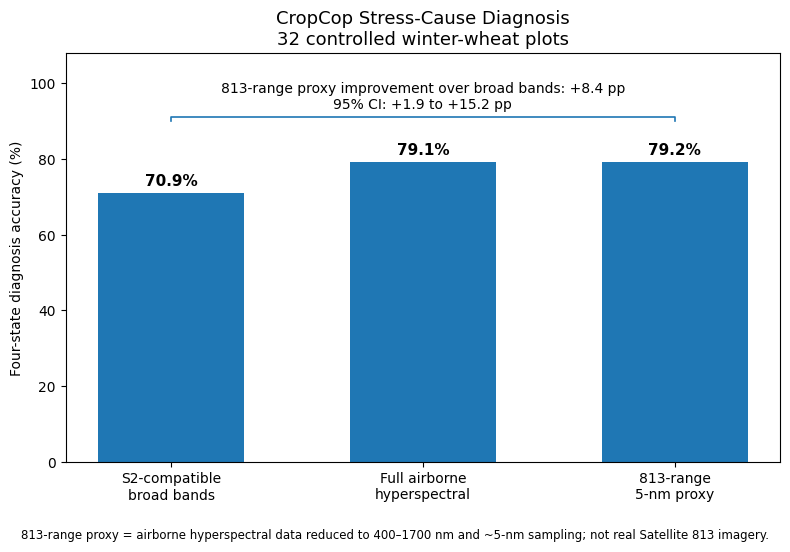

In [41]:
# ============================================================
# Diagnosis Step 7J — FINAL judge-facing hyperspectral figure
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd


# ------------------------------------------------------------
# 1. Collect three key results
# ------------------------------------------------------------

figure_data = pd.concat(
    [
        diagnosis_results_final[
            diagnosis_results_final["Sensor input"].isin([
                "Airborne-derived S2-compatible",
                "Hyperspectral"
            ])
        ],
        proxy_result
    ],
    ignore_index=True
)

name_map = {
    "Airborne-derived S2-compatible":
        "S2-compatible\nbroad bands",

    "Hyperspectral":
        "Full airborne\nhyperspectral",

    "813-range 5-nm HSI proxy":
        "813-range\n5-nm proxy"
}

figure_data["Display_name"] = (
    figure_data["Sensor input"]
    .map(name_map)
)


# ------------------------------------------------------------
# 2. Extract paired CI:
#    813 proxy vs S2-compatible
# ------------------------------------------------------------

ci_row = proxy_bootstrap_final[
    (
        proxy_bootstrap_final["Comparison"]
        .str.contains(
            "813-range 5-nm HSI proxy - Airborne-derived",
            regex=False
        )
    )
    &
    (
        proxy_bootstrap_final["Metric"]
        == "Four_state_accuracy"
    )
].iloc[0]

difference = ci_row["Observed_difference"] * 100
ci_low = ci_row["95% CI low"] * 100
ci_high = ci_row["95% CI high"] * 100


# ------------------------------------------------------------
# 3. Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5.5)
)

x = list(range(len(figure_data)))

accuracy_percent = (
    figure_data["Four-state accuracy"]
    .to_numpy()
    * 100
)

bars = ax.bar(
    x,
    accuracy_percent,
    width=0.58
)


# Accuracy values
for i, value in enumerate(accuracy_percent):

    ax.text(
        i,
        value + 1.2,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )


ax.set_xticks(x)

ax.set_xticklabels(
    figure_data["Display_name"]
)

ax.set_ylabel(
    "Four-state diagnosis accuracy (%)"
)

ax.set_ylim(
    0,
    108
)

ax.set_title(
    "CropCop Stress-Cause Diagnosis\n"
    "32 controlled winter-wheat plots",
    fontsize=13
)


# ------------------------------------------------------------
# 4. Statistical comparison bracket:
#    S2-compatible vs 813-range proxy
# ------------------------------------------------------------

y_bracket = 91

ax.plot(
    [0, 0, 2, 2],
    [
        y_bracket - 1,
        y_bracket,
        y_bracket,
        y_bracket - 1
    ],
    linewidth=1.2
)

ax.text(
    1,
    y_bracket + 1.5,
    (
        f"813-range proxy improvement over broad bands: "
        f"+{difference:.1f} pp\n"
        f"95% CI: +{ci_low:.1f} to +{ci_high:.1f} pp"
    ),
    ha="center",
    va="bottom",
    fontsize=10
)


# ------------------------------------------------------------
# 5. Scientific caveat
# ------------------------------------------------------------

fig.text(
    0.5,
    0.01,
    (
        "813-range proxy = airborne hyperspectral data reduced to "
        "400–1700 nm and ~5-nm sampling; not real Satellite 813 imagery."
    ),
    ha="center",
    fontsize=8.5
)

plt.tight_layout(
    rect=[0, 0.05, 1, 1]
)

plt.show()

### Hyperspectral diagnosis and Satellite 813 relevance

CropCop's diagnosis capability was evaluated on 32 controlled winter-wheat plots with
known nitrogen and water treatments.

Using the same frozen nested cross-validation protocol:

- Airborne-derived Sentinel-2-compatible broad bands: **70.9%**
- Full airborne hyperspectral: **79.1%**
- 813-range 5-nm hyperspectral proxy: **79.2%**

The 813-range proxy was created by reducing the airborne hyperspectral measurements to
the **400–1700 nm range with approximately 5-nm sampling**, matching the published
spectral range and sampling concept of Satellite 813.

Compared with the broad Sentinel-2-compatible representation, the 813-range proxy
improved four-state diagnosis by **+8.4 percentage points**
(95% CI: **+1.9 to +15.2 pp**).

Its performance was essentially identical to full airborne HSI
(**79.2% vs 79.1%**), with no clear difference between them.

This supports the idea that the diagnostic information used by CropCop remains
available after reducing the spectra to an 813-relevant range and sampling scale.

However, this is **not a validation of real Satellite 813 imagery**. The proxy does not
reproduce the actual satellite's atmospheric effects, spatial mixing at 20 m,
signal-to-noise ratio, or exact spectral response functions.

The hyperspectral advantage also depends on the stress definition. When nitrogen stress
was defined using measured NNI ≤ 0.80 rather than fertilizer treatment, HSI did not
outperform the broad S2-compatible representation.

Therefore, the PoC supports hyperspectral data as a valuable diagnostic layer, but does
not claim that hyperspectral information is universally superior or sufficient on its
own.